**Step 1. Import libraries**

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

**Step 2. Load dataset**

In [2]:
df = pd.read_csv("Womens Clothing E-Commerce Reviews.csv")

In [3]:
df

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses
...,...,...,...,...,...,...,...,...,...,...,...
23481,23481,1104,34,Great dress for many occasions,I was very happy to snag this dress at such a ...,5,1,0,General Petite,Dresses,Dresses
23482,23482,862,48,Wish it was made of cotton,"It reminds me of maternity clothes. soft, stre...",3,1,0,General Petite,Tops,Knits
23483,23483,1104,31,"Cute, but see through","This fit well, but the top was very see throug...",3,0,1,General Petite,Dresses,Dresses
23484,23484,1084,28,"Very cute dress, perfect for summer parties an...",I bought this dress for a wedding i have this ...,3,1,2,General,Dresses,Dresses


In [4]:
print(df.head())

   Unnamed: 0  Clothing ID  Age                    Title  \
0           0          767   33                      NaN   
1           1         1080   34                      NaN   
2           2         1077   60  Some major design flaws   
3           3         1049   50         My favorite buy!   
4           4          847   47         Flattering shirt   

                                         Review Text  Rating  Recommended IND  \
0  Absolutely wonderful - silky and sexy and comf...       4                1   
1  Love this dress!  it's sooo pretty.  i happene...       5                1   
2  I had such high hopes for this dress and reall...       3                0   
3  I love, love, love this jumpsuit. it's fun, fl...       5                1   
4  This shirt is very flattering to all due to th...       5                1   

   Positive Feedback Count   Division Name Department Name Class Name  
0                        0       Initmates        Intimate  Intimates  
1       

In [5]:
print(df.shape)

(23486, 11)


In [6]:
print(df.columns)

Index(['Unnamed: 0', 'Clothing ID', 'Age', 'Title', 'Review Text', 'Rating',
       'Recommended IND', 'Positive Feedback Count', 'Division Name',
       'Department Name', 'Class Name'],
      dtype='str')


**Step 3. Select required columns**

In [7]:
df = df[['Review Text', 'Rating']]

print(df.head())

                                         Review Text  Rating
0  Absolutely wonderful - silky and sexy and comf...       4
1  Love this dress!  it's sooo pretty.  i happene...       5
2  I had such high hopes for this dress and reall...       3
3  I love, love, love this jumpsuit. it's fun, fl...       5
4  This shirt is very flattering to all due to th...       5


**Step 4. Clean the dataset**

In [8]:
df = df.dropna()

In [9]:
df

,Review Text,Rating
0,Absolutely wonderful - silky and sexy and comf...,4
1,Love this dress! it's sooo pretty. i happene...,5
2,I had such high hopes for this dress and reall...,3
3,"I love, love, love this jumpsuit. it's fun, fl...",5
4,This shirt is very flattering to all due to th...,5
...,...,...
23481,I was very happy to snag this dress at such a ...,5
23482,"It reminds me of maternity clothes. soft, stre...",3
23483,"This fit well, but the top was very see throug...",3
23484,I bought this dress for a wedding i have this ...,3


In [10]:
df = df[df['Rating'] != 3]

In [11]:
df

,Review Text,Rating
0,Absolutely wonderful - silky and sexy and comf...,4
1,Love this dress! it's sooo pretty. i happene...,5
3,"I love, love, love this jumpsuit. it's fun, fl...",5
4,This shirt is very flattering to all due to th...,5
5,"I love tracy reese dresses, but this one is no...",2
...,...,...
23477,I'm so impressed with the beautiful color comb...,4
23478,I was surprised at the positive reviews for th...,1
23479,So i wasn't sure about ordering this skirt bec...,5
23481,I was very happy to snag this dress at such a ...,5


In [12]:
print(df.isnull().sum())

Review Text    0
Rating         0
dtype: int64


In [13]:
print(df.shape)

(19818, 2)


**Step 5. Create sentiment labels**

In [14]:
df['Sentiment'] = df['Rating'].apply(
    lambda x: 1 if x >= 4 else 0
)

print(df[['Review Text', 'Rating', 'Sentiment']].head())

                                         Review Text  Rating  Sentiment
0  Absolutely wonderful - silky and sexy and comf...       4          1
1  Love this dress!  it's sooo pretty.  i happene...       5          1
3  I love, love, love this jumpsuit. it's fun, fl...       5          1
4  This shirt is very flattering to all due to th...       5          1
5  I love tracy reese dresses, but this one is no...       2          0


**Step 6. Check positive and negative reviews**

Sentiment
1    17448
0     2370
Name: count, dtype: int64


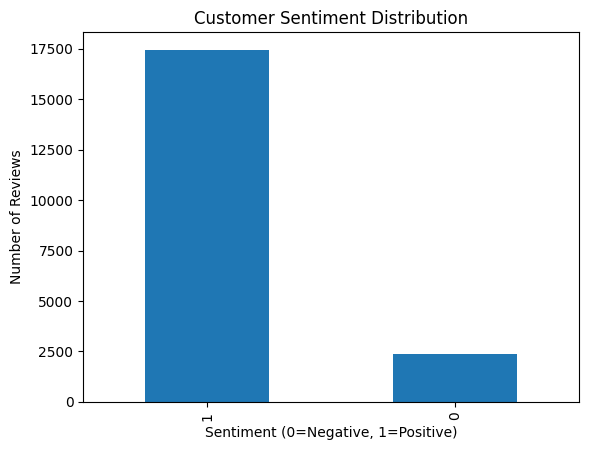

In [15]:
print(df['Sentiment'].value_counts())

df['Sentiment'].value_counts().plot(
    kind='bar',
    title='Customer Sentiment Distribution'
)

plt.xlabel('Sentiment (0=Negative, 1=Positive)')
plt.ylabel('Number of Reviews')
plt.show()

**Step 7. Separate input and output**

In [16]:
X = df['Review Text'].astype(str) #X = Customer review text (input).
y = df['Sentiment'] #y = Sentiment (output).

print("Input shape:", X.shape)
print("Output shape:", y.shape)

Input shape: (19818,)
Output shape: (19818,)


**Step 8. Split training and testing data**

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 15854
Testing samples: 3964


**Step 9. Tokenization**

In [18]:
tokenizer = Tokenizer(num_words=10000, oov_token="<OOV>")

tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)

X_test_seq = tokenizer.texts_to_sequences(X_test)

print(X_train_seq[0])

[58, 26, 117, 227, 4, 5, 34, 349, 956, 122, 2, 396, 524, 84, 5, 69, 523, 3, 38, 547, 276, 205]


**Purpose: LSTM cannot directly understand English words. So we convert words into numbers.**

**Step 10. Padding**

Make all review sequences equal length

In [19]:
max_length = 100

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

print("Training shape:", X_train_pad.shape)
print("Testing shape:", X_test_pad.shape)

Training shape: (15854, 100)
Testing shape: (3964, 100)


**Step 11. Build LSTM model**

In [20]:
model = Sequential()

model.add(
    Embedding(
        input_dim=10000,
        output_dim=64
    )
)

model.add(LSTM(64))

model.add(Dropout(0.3))

model.add(Dense(1, activation='sigmoid'))

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [21]:
model.build(input_shape=(None, 100))

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ (None, 100, 64)             │         640,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ (None, 64)                  │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 673,089 (2.57 MB)

 Trainable params: 673,089 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

**step 12. Train your LSTM model**

In [22]:
history = model.fit(
    X_train_pad,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/5
397/397 ━━━━━━━━━━━━━━━━━━━━ 17s 36ms/step - accuracy: 0.8816 - loss: 0.3726 - val_accuracy: 0.8742 - val_loss: 0.3789
Epoch 2/5
397/397 ━━━━━━━━━━━━━━━━━━━━ 14s 35ms/step - accuracy: 0.8820 - loss: 0.3639 - val_accuracy: 0.8735 - val_loss: 0.3770
Epoch 3/5
397/397 ━━━━━━━━━━━━━━━━━━━━ 14s 35ms/step - accuracy: 0.8826 - loss: 0.3551 - val_accuracy: 0.8704 - val_loss: 0.3742
Epoch 4/5
397/397 ━━━━━━━━━━━━━━━━━━━━ 14s 35ms/step - accuracy: 0.8903 - loss: 0.3192 - val_accuracy: 0.8430 - val_loss: 0.3046
Epoch 5/5
397/397 ━━━━━━━━━━━━━━━━━━━━ 14s 35ms/step - accuracy: 0.8967 - loss: 0.2848 - val_accuracy: 0.8461 - val_loss: 0.3450


**Accuracy graph**

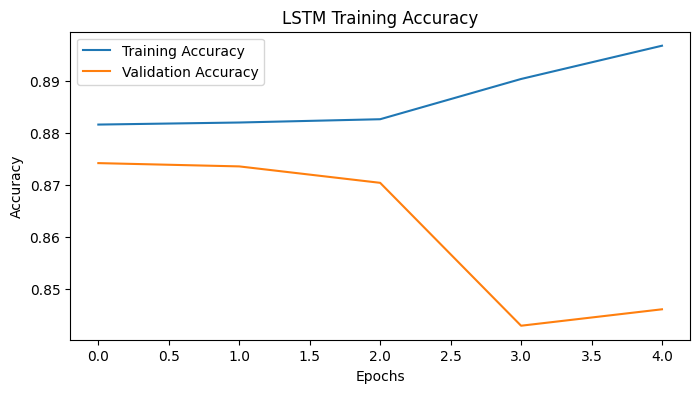

In [23]:
plt.figure(figsize=(8, 4))

plt.plot(history.history['accuracy'],
         label='Training Accuracy')

plt.plot(history.history['val_accuracy'],
         label='Validation Accuracy')

plt.title('LSTM Training Accuracy')

plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.legend()
plt.show()

**Model Evaluation**

In [24]:
loss, accuracy = model.evaluate(
    X_test_pad,
    y_test
)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy * 100, "%")

124/124 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.8524 - loss: 0.3287
Test Loss: 0.328734427690506
Test Accuracy: 85.24218201637268 %


**Classification Report**

In [25]:
y_pred = model.predict(X_test_pad)

y_pred = (y_pred >= 0.5).astype(int)

from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=['Negative', 'Positive']
))

124/124 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step
              precision    recall  f1-score   support

    Negative       0.22      0.09      0.13       474
    Positive       0.89      0.96      0.92      3490

    accuracy                           0.85      3964
   macro avg       0.55      0.52      0.52      3964
weighted avg       0.81      0.85      0.82      3964



**Calculate class weights**

In [26]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print(class_weights)

{np.int64(0): np.float64(4.180907172995781), np.int64(1): np.float64(0.5679180398337871)}


**Retrain your LSTM model**

In [27]:
model = Sequential([
    Embedding(10000, 64),
    LSTM(64),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [28]:
history = model.fit(
    X_train_pad,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.2,
    class_weight=class_weights
)

Epoch 1/5
397/397 ━━━━━━━━━━━━━━━━━━━━ 16s 35ms/step - accuracy: 0.5563 - loss: 0.6898 - val_accuracy: 0.3050 - val_loss: 0.7006
Epoch 2/5
397/397 ━━━━━━━━━━━━━━━━━━━━ 14s 34ms/step - accuracy: 0.5001 - loss: 0.6737 - val_accuracy: 0.8073 - val_loss: 0.6741
Epoch 3/5
397/397 ━━━━━━━━━━━━━━━━━━━━ 14s 34ms/step - accuracy: 0.6678 - loss: 0.6527 - val_accuracy: 0.8742 - val_loss: 0.4888
Epoch 4/5
397/397 ━━━━━━━━━━━━━━━━━━━━ 14s 35ms/step - accuracy: 0.4796 - loss: 0.6813 - val_accuracy: 0.8657 - val_loss: 0.6358
Epoch 5/5
397/397 ━━━━━━━━━━━━━━━━━━━━ 14s 34ms/step - accuracy: 0.5366 - loss: 0.6169 - val_accuracy: 0.1728 - val_loss: 0.8181


**Evaluate the improved model**

In [29]:
loss, accuracy = model.evaluate(
    X_test_pad,
    y_test
)

print("New Test Loss:", loss)

print("New Test Accuracy:", accuracy * 100, "%")

124/124 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.1607 - loss: 0.8213
New Test Loss: 0.8212875127792358
New Test Accuracy: 16.069626808166504 %


In [30]:
from sklearn.metrics import classification_report

y_pred = model.predict(X_test_pad)

y_pred = (y_pred >= 0.5).astype(int)

print(classification_report(
    y_test,
    y_pred,
    target_names=['Negative', 'Positive']
))

124/124 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step
              precision    recall  f1-score   support

    Negative       0.12      0.99      0.22       474
    Positive       0.97      0.05      0.09      3490

    accuracy                           0.16      3964
   macro avg       0.55      0.52      0.16      3964
weighted avg       0.87      0.16      0.11      3964



**Confusion Matrix**

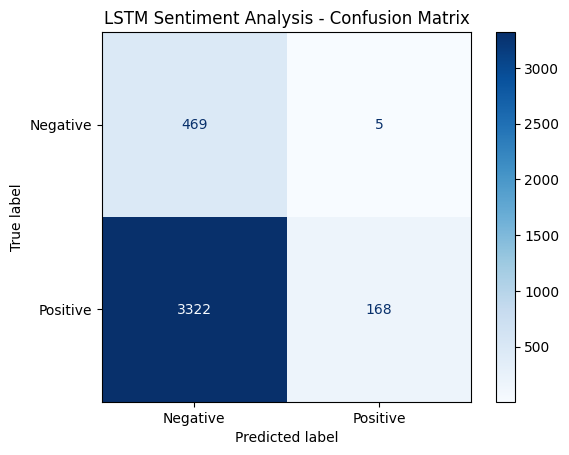

In [31]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Negative', 'Positive']
)

disp.plot(cmap='Blues')
plt.title("LSTM Sentiment Analysis - Confusion Matrix")
plt.show()

**Create a prediction function**

In [32]:
def predict_sentiment(review):

    # Convert text into sequence
    sequence = tokenizer.texts_to_sequences([review])

    # Padding
    padded = pad_sequences(
        sequence,
        maxlen=100,
        padding='post',
        truncating='post'
    )

    # Prediction
    prediction = model.predict(padded, verbose=0)[0][0]

    # Sentiment result
    if prediction >= 0.5:
        print("Positive Review 😊")
    else:
        print("Negative Review 😞")

    print("Prediction Score:", round(float(prediction), 4))

**Test a Positive review**

In [33]:
predict_sentiment(
    "This dress is beautiful and the quality is excellent. I love it."
)

Negative Review 😞
Prediction Score: 0.4139


**Test a Negative review**

In [34]:
predict_sentiment(
    "The product quality is very poor. I am disappointed with this purchase."
)

Negative Review 😞
Prediction Score: 0.4139


**Test My own review**

In [36]:
my_review = input("Enter your customer review: ")

predict_sentiment(my_review)

Enter your customer review:  this cloth is very bad


Negative Review 😞
Prediction Score: 0.4139


In [37]:
review = "this cloth is very good and beautiful"

sequence = tokenizer.texts_to_sequences([review])

print("Original Review:", review)
print("Tokenized Sequence:", sequence)

print("\nRecognized Words:")

for word in review.lower().split():
    print(word, ":", tokenizer.word_index.get(word, "Unknown"))

Original Review: this cloth is very good and beautiful
Tokenized Sequence: [[8, 1245, 7, 24, 115, 4, 72]]

Recognized Words:
this : 8
cloth : 1245
is : 7
very : 24
good : 115
and : 4
beautiful : 72


**Check model predictions**

In [38]:
test_reviews = [
    "This dress is beautiful and excellent",
    "I love this product and its quality",
    "Very good quality and comfortable dress",
    "The product is very bad and disappointing",
    "Poor quality and waste of money"
]

for review in test_reviews:
    sequence = tokenizer.texts_to_sequences([review])

    padded = pad_sequences(
        sequence,
        maxlen=100,
        padding='post',
        truncating='post'
    )

    score = float(model.predict(padded, verbose=0)[0][0])

    print("\nReview:", review)
    print("Positive Score:", round(score, 4))
    print("Prediction:", "Positive" if score >= 0.5 else "Negative")


Review: This dress is beautiful and excellent
Positive Score: 0.4139
Prediction: Negative

Review: I love this product and its quality
Positive Score: 0.4139
Prediction: Negative

Review: Very good quality and comfortable dress
Positive Score: 0.4139
Prediction: Negative

Review: The product is very bad and disappointing
Positive Score: 0.4139
Prediction: Negative

Review: Poor quality and waste of money
Positive Score: 0.4139
Prediction: Negative


In [39]:
thresholds = [0.3, 0.4, 0.5, 0.6]

for threshold in thresholds:

    y_pred_threshold = (
        model.predict(X_test_pad, verbose=0).flatten() >= threshold
    ).astype(int)

    print("\nThreshold:", threshold)

    print(classification_report(
        y_test,
        y_pred_threshold,
        target_names=['Negative', 'Positive']
    ))


Threshold: 0.3
              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00       474
    Positive       0.88      1.00      0.94      3490

    accuracy                           0.88      3964
   macro avg       0.44      0.50      0.47      3964
weighted avg       0.78      0.88      0.82      3964


Threshold: 0.4
              precision    recall  f1-score   support

    Negative       0.15      0.05      0.08       474
    Positive       0.88      0.96      0.92      3490

    accuracy                           0.85      3964
   macro avg       0.52      0.51      0.50      3964
weighted avg       0.79      0.85      0.82      3964


Threshold: 0.5
              precision    recall  f1-score   support

    Negative       0.12      0.99      0.22       474
    Positive       0.97      0.05      0.09      3490

    accuracy                           0.16      3964
   macro avg       0.55      0.52      0.16      3964
weighted avg       0.87   

In [41]:
def predict_sentiment(review):

    sequence = tokenizer.texts_to_sequences([review])

    padded = pad_sequences(
        sequence,
        maxlen=100,
        padding='post',
        truncating='post'
    )

    score = float(model.predict(padded, verbose=0)[0][0])

    threshold = 0.3

    if score >= threshold:
        print("Positive Review 😊")
    else:
        print("Negative Review 😞")

    print("Positive Score:", round(score, 4))
    print("Threshold:", threshold)

In [42]:
predict_sentiment(
    "This cloth is very good and beautiful"
)

Positive Review 😊
Positive Score: 0.4139
Threshold: 0.3


In [43]:
test_reviews = [
    "beautiful",
    "good",
    "excellent",
    "very good",
    "good and beautiful",
    "this dress is beautiful and excellent",
    "this cloth is very good and beautiful"
]

for review in test_reviews:
    print("\nReview:", review)
    predict_sentiment(review)


Review: beautiful
Positive Review 😊
Positive Score: 0.4139
Threshold: 0.3

Review: good
Positive Review 😊
Positive Score: 0.4139
Threshold: 0.3

Review: excellent
Positive Review 😊
Positive Score: 0.4139
Threshold: 0.3

Review: very good
Positive Review 😊
Positive Score: 0.4139
Threshold: 0.3

Review: good and beautiful
Positive Review 😊
Positive Score: 0.4139
Threshold: 0.3

Review: this dress is beautiful and excellent
Positive Review 😊
Positive Score: 0.4139
Threshold: 0.3

Review: this cloth is very good and beautiful
Positive Review 😊
Positive Score: 0.4139
Threshold: 0.3


In [44]:
print("Training Data Sentiment Count:")

print(
    pd.Series(y_train)
    .value_counts()
    .rename(index={0: "Negative", 1: "Positive"})
)

print("\nSample Positive Reviews:")

for review in X_train[y_train == 1][:5]:
    print("-", review)

print("\nSample Negative Reviews:")

for review in X_train[y_train == 0][:5]:
    print("-", review)

Training Data Sentiment Count:
Sentiment
Positive    13958
Negative     1896
Name: count, dtype: int64

Sample Positive Reviews:
- These are super comfy and a great fitting everyday short. the embroidery gives them a nice touch. i am ordering another pair!
- This is a cute dress, it fits well. i have a bust do it's not as "loose" as it is on the model. runs short. i'm 5'8" solid size 10
- I loved the look of this dress online, and it's everything i hoped and more in person.
i'm 5'10", 155# and pear-shaped.
while the bottom of this dress is voluminous, it definitely did not have a pregnant fit on my body shape.
the length was absolutely perfect, it wasn't scratchy in the least. i got compliments on the dress all day long. wore with a pair of cowboy boots while wine tasting in napa.
- I really love this dress. it's very flattering for all body types - i'm 5'4", 120 and i purchased a small. it also looks really cute with a stretchy belt. in the picture - it doesn't show this, but it has t

In [45]:
from collections import Counter
import re

positive_text = " ".join(X_train[y_train == 1])
negative_text = " ".join(X_train[y_train == 0])

def get_common_words(text):
    words = re.findall(r'\b[a-z]+\b', text.lower())
    return Counter(words).most_common(20)

print("TOP 20 POSITIVE WORDS")
print(get_common_words(positive_text))

print("\nTOP 20 NEGATIVE WORDS")
print(get_common_words(negative_text))

TOP 20 POSITIVE WORDS
[('the', 44807), ('i', 41440), ('and', 30865), ('it', 30023), ('a', 27349), ('is', 19526), ('this', 15788), ('to', 15067), ('in', 12761), ('but', 9542), ('on', 9036), ('for', 8734), ('with', 8697), ('of', 7931), ('so', 7510), ('my', 6924), ('dress', 6362), ('love', 6196), ('that', 6076), ('was', 5760)]

TOP 20 NEGATIVE WORDS
[('the', 7456), ('i', 5409), ('it', 4259), ('and', 3739), ('a', 3049), ('this', 2319), ('is', 2285), ('to', 2089), ('was', 1902), ('in', 1728), ('but', 1507), ('on', 1446), ('of', 1337), ('not', 1167), ('so', 1023), ('for', 1001), ('dress', 921), ('t', 909), ('that', 845), ('like', 822)]


In [46]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from collections import Counter
import re

stop_words = set(ENGLISH_STOP_WORDS)

# Keep sentiment-changing words
keep_words = {'not', 'no', 'nor', 'but', 'never'}

stop_words = stop_words - keep_words

def get_useful_words(text):
    words = re.findall(r'\b[a-z]+\b', text.lower())
    words = [word for word in words if word not in stop_words]

    return Counter(words).most_common(20)

print("USEFUL POSITIVE WORDS:")
print(get_useful_words(positive_text))

print("\nUSEFUL NEGATIVE WORDS:")
print(get_useful_words(negative_text))

USEFUL POSITIVE WORDS:
[('but', 9542), ('dress', 6362), ('love', 6196), ('size', 5717), ('s', 5634), ('not', 5362), ('t', 5083), ('fit', 4578), ('wear', 4327), ('great', 4305), ('m', 4301), ('like', 3919), ('just', 3184), ('color', 2930), ('small', 2850), ('perfect', 2815), ('fabric', 2648), ('little', 2609), ('soft', 2354), ('flattering', 2302)]

USEFUL NEGATIVE WORDS:
[('but', 1507), ('not', 1167), ('dress', 921), ('t', 909), ('like', 822), ('s', 646), ('fabric', 574), ('fit', 546), ('size', 538), ('just', 520), ('m', 424), ('small', 414), ('look', 412), ('ordered', 411), ('love', 382), ('really', 381), ('shirt', 359), ('wear', 343), ('material', 336), ('looks', 317)]


In [47]:
import re

def clean_review(text):

    text = text.lower()

    # Expand contractions
    text = re.sub(r"won't", "will not", text)
    text = re.sub(r"can't", "cannot", text)
    text = re.sub(r"n't", " not", text)
    text = re.sub(r"'re", " are", text)
    text = re.sub(r"'ve", " have", text)
    text = re.sub(r"'ll", " will", text)
    text = re.sub(r"'m", " am", text)
    text = re.sub(r"'d", " would", text)

    # Remove special characters and numbers
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [48]:
sample = "I don't like this dress. It's not good!"

print(clean_review(sample))

i do not like this dress it s not good


In [49]:
import re

def clean_review(text):

    text = text.lower()

    # Expand contractions
    text = re.sub(r"it's", "it is", text)
    text = re.sub(r"don't", "do not", text)
    text = re.sub(r"doesn't", "does not", text)
    text = re.sub(r"didn't", "did not", text)
    text = re.sub(r"won't", "will not", text)
    text = re.sub(r"can't", "cannot", text)
    text = re.sub(r"n't", " not", text)
    text = re.sub(r"'re", " are", text)
    text = re.sub(r"'ve", " have", text)
    text = re.sub(r"'ll", " will", text)
    text = re.sub(r"'m", " am", text)
    text = re.sub(r"'d", " would", text)

    # Remove special characters
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [50]:
sample = "I don't like this dress. It's not good!"

print(clean_review(sample))

i do not like this dress it is not good


In [51]:
X_train_clean = X_train.apply(clean_review)
X_test_clean = X_test.apply(clean_review)

print("Original Review:")
print(X_train.iloc[0])

print("\nCleaned Review:")
print(X_train_clean.iloc[0])

Original Review:
These are super comfy and a great fitting everyday short. the embroidery gives them a nice touch. i am ordering another pair!

Cleaned Review:
these are super comfy and a great fitting everyday short the embroidery gives them a nice touch i am ordering another pair


In [52]:
tokenizer_new = Tokenizer(
    num_words=10000,
    oov_token="<OOV>"
)

tokenizer_new.fit_on_texts(X_train_clean)

print("Vocabulary Size:", len(tokenizer_new.word_index))

Vocabulary Size: 11735


In [53]:
X_train_seq = tokenizer_new.texts_to_sequences(X_train_clean)
X_test_seq = tokenizer_new.texts_to_sequences(X_test_clean)

print("Training Sequence:", X_train_seq[0])
print("Testing Sequence:", X_test_seq[0])

Training Sequence: [56, 27, 121, 217, 4, 6, 34, 336, 897, 126, 2, 383, 497, 83, 6, 69, 496, 3, 18, 517, 264, 198]
Testing Sequence: [3, 931, 8, 42, 627, 2, 9855, 1658, 4, 26, 254, 9, 205, 20, 25, 3, 19, 2920, 8, 349, 3, 1336, 8, 52, 6, 2367, 68, 5, 7, 11, 361, 4, 4542, 63, 633, 3, 194, 42, 9, 6, 25, 68, 5, 132, 523, 32, 1080, 10, 2, 849, 4, 2, 211, 3, 205, 8, 182, 9, 30, 6, 1, 16, 2, 706, 101, 698, 3, 24, 4052, 148, 2, 491, 225, 20, 196, 7, 6, 404, 4, 106, 260, 2, 7, 335, 3, 176, 309, 9, 33, 8, 1708, 1051, 182, 3, 135, 2, 1, 308, 350]


In [54]:
X_train_pad_new = pad_sequences(
    X_train_seq,
    maxlen=100,
    padding='post',
    truncating='post'
)

X_test_pad_new = pad_sequences(
    X_test_seq,
    maxlen=100,
    padding='post',
    truncating='post'
)

print("Training Shape:", X_train_pad_new.shape)
print("Testing Shape:", X_test_pad_new.shape)

Training Shape: (15854, 100)
Testing Shape: (3964, 100)


In [55]:
X_train_pad_new = pad_sequences(
    X_train_seq,
    maxlen=100,
    padding='post',
    truncating='post'
)

X_test_pad_new = pad_sequences(
    X_test_seq,
    maxlen=100,
    padding='post',
    truncating='post'
)

print("Training Shape:", X_train_pad_new.shape)
print("Testing Shape:", X_test_pad_new.shape)

Training Shape: (15854, 100)
Testing Shape: (3964, 100)


In [56]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

class_weights_new = dict(zip(classes, weights))

print(class_weights_new)

{np.int64(0): np.float64(4.180907172995781), np.int64(1): np.float64(0.5679180398337871)}


In [57]:
model_new = Sequential([
    Embedding(10000, 64),
    LSTM(64),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

model_new.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history_new = model_new.fit(
    X_train_pad_new,
    y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.2,
    class_weight=class_weights_new
)

Epoch 1/5
397/397 ━━━━━━━━━━━━━━━━━━━━ 17s 35ms/step - accuracy: 0.5254 - loss: 0.6960 - val_accuracy: 0.8742 - val_loss: 0.6067
Epoch 2/5
397/397 ━━━━━━━━━━━━━━━━━━━━ 14s 35ms/step - accuracy: 0.4972 - loss: 0.6940 - val_accuracy: 0.2646 - val_loss: 0.7009
Epoch 3/5
397/397 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - accuracy: 0.4530 - loss: 0.6790 - val_accuracy: 0.2353 - val_loss: 0.7155
Epoch 4/5
397/397 ━━━━━━━━━━━━━━━━━━━━ 14s 35ms/step - accuracy: 0.6110 - loss: 0.6026 - val_accuracy: 0.2898 - val_loss: 0.7235
Epoch 5/5
397/397 ━━━━━━━━━━━━━━━━━━━━ 14s 35ms/step - accuracy: 0.7718 - loss: 0.5499 - val_accuracy: 0.3677 - val_loss: 0.6314


In [58]:
test_loss, test_accuracy = model_new.evaluate(
    X_test_pad_new,
    y_test
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100)

124/124 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.3522 - loss: 0.6394
Test Loss: 0.6393796801567078
Test Accuracy: 35.21695137023926


In [59]:
from sklearn.metrics import classification_report

y_pred_prob = model_new.predict(X_test_pad_new)

y_pred = (y_pred_prob >= 0.5).astype(int)

print(classification_report(
    y_test,
    y_pred,
    target_names=['Negative', 'Positive']
))

124/124 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step
              precision    recall  f1-score   support

    Negative       0.13      0.82      0.23       474
    Positive       0.92      0.29      0.44      3490

    accuracy                           0.35      3964
   macro avg       0.53      0.55      0.34      3964
weighted avg       0.83      0.35      0.42      3964



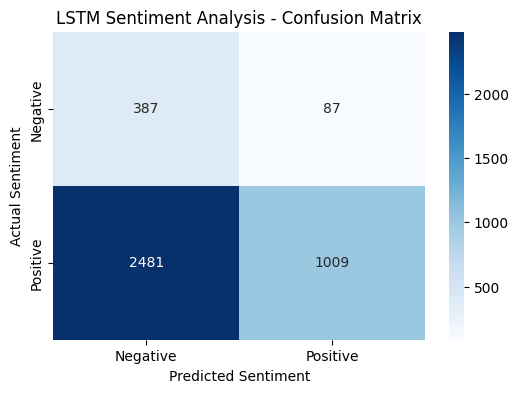

In [60]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)

plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')
plt.title('LSTM Sentiment Analysis - Confusion Matrix')

plt.show()

In [61]:
def predict_sentiment(review):

    # Step 1: Clean the input review
    cleaned_review = clean_review(review)

    # Step 2: Convert text into sequence
    sequence = tokenizer_new.texts_to_sequences([cleaned_review])

    # Step 3: Apply padding
    padded = pad_sequences(
        sequence,
        maxlen=100,
        padding='post',
        truncating='post'
    )

    # Step 4: Predict sentiment
    prediction = model_new.predict(padded, verbose=0)[0][0]

    # Step 5: Classify sentiment
    if prediction >= 0.5:
        print("Positive Review 😊")
    else:
        print("Negative Review 😞")

    print("Prediction Score:", round(float(prediction), 4))

In [62]:
predict_sentiment("This dress is beautiful and excellent")

predict_sentiment("The product is very bad and disappointing")

predict_sentiment("I love this product and its quality")

predict_sentiment("Poor quality and waste of money")

predict_sentiment("The fabric is soft and comfortable")

Negative Review 😞
Prediction Score: 0.4725
Negative Review 😞
Prediction Score: 0.4725
Negative Review 😞
Prediction Score: 0.4725
Negative Review 😞
Prediction Score: 0.4725
Negative Review 😞
Prediction Score: 0.4725


In [63]:
test_reviews = [
    "This dress is beautiful and excellent",
    "The product is very bad and disappointing",
    "I love this product and its quality",
    "Poor quality and waste of money",
    "The fabric is soft and comfortable"
]

for review in test_reviews:

    cleaned = clean_review(review)

    sequence = tokenizer_new.texts_to_sequences([cleaned])

    padded = pad_sequences(
        sequence,
        maxlen=100,
        padding='post',
        truncating='post'
    )

    print("\nOriginal:", review)
    print("Cleaned:", cleaned)
    print("Sequence:", sequence)
    print("Non-zero tokens:", np.count_nonzero(padded))


Original: This dress is beautiful and excellent
Cleaned: this dress is beautiful and excellent
Sequence: [[8, 21, 7, 72, 4, 725]]
Non-zero tokens: 6

Original: The product is very bad and disappointing
Cleaned: the product is very bad and disappointing
Sequence: [[2, 733, 7, 26, 480, 4, 993]]
Non-zero tokens: 7

Original: I love this product and its quality
Cleaned: i love this product and its quality
Sequence: [[3, 23, 8, 733, 4, 234, 98]]
Non-zero tokens: 7

Original: Poor quality and waste of money
Cleaned: poor quality and waste of money
Sequence: [[986, 98, 4, 1425, 16, 825]]
Non-zero tokens: 6

Original: The fabric is soft and comfortable
Cleaned: the fabric is soft and comfortable
Sequence: [[2, 45, 7, 58, 4, 62]]
Non-zero tokens: 6


In [64]:
# Prepare all cleaned reviews
cleaned_reviews = [clean_review(review) for review in test_reviews]

# Convert text into sequences
sequences = tokenizer_new.texts_to_sequences(cleaned_reviews)

# Apply padding
padded_reviews = pad_sequences(
    sequences,
    maxlen=100,
    padding='post',
    truncating='post'
)

# Predict all reviews
scores = model_new.predict(padded_reviews, verbose=0)

# Display predictions
for review, score in zip(test_reviews, scores):

    score = float(score[0])

    if score >= 0.5:
        sentiment = "Positive 😊"
    else:
        sentiment = "Negative 😞"

    print("\nReview:", review)
    print("Sentiment:", sentiment)
    print("Prediction Score:", round(score, 4))


Review: This dress is beautiful and excellent
Sentiment: Negative 😞
Prediction Score: 0.4725

Review: The product is very bad and disappointing
Sentiment: Negative 😞
Prediction Score: 0.4725

Review: I love this product and its quality
Sentiment: Negative 😞
Prediction Score: 0.4725

Review: Poor quality and waste of money
Sentiment: Negative 😞
Prediction Score: 0.4725

Review: The fabric is soft and comfortable
Sentiment: Negative 😞
Prediction Score: 0.4725


In [65]:
# Check model predictions for different inputs

print("Model Input Shape:", model_new.input_shape)
print("Model Output Shape:", model_new.output_shape)

print("\nFirst review padded input:")
print(padded_reviews[0][:15])

print("\nSecond review padded input:")
print(padded_reviews[1][:15])

print("\nAre both inputs identical?")
print(np.array_equal(padded_reviews[0], padded_reviews[1]))

print("\nPrediction scores:")
print(model_new.predict(padded_reviews, verbose=0).flatten())

Model Input Shape: (None, 100)
Model Output Shape: (None, 1)

First review padded input:
[  8  21   7  72   4 725   0   0   0   0   0   0   0   0   0]

Second review padded input:
[  2 733   7  26 480   4 993   0   0   0   0   0   0   0   0]

Are both inputs identical?
False

Prediction scores:
[0.4725498  0.47254977 0.4725497  0.47254977 0.47254983]


In [66]:
model_new.summary()

print("\nDense Layer Weights:")
print(model_new.layers[-1].get_weights())

print("\nLSTM Layer Weights:")
print(model_new.layers[1].get_weights())

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)              │ (None, 100, 64)             │         640,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_2 (LSTM)                        │ (None, 64)                  │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,019,269 (7.70 MB)

 Trainable params: 673,089 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,346,180 (5.14 MB)


Dense Layer Weights:
[array([[ 0.1668475 ],
       [ 0.12153198],
       [-0.20328519],
       [-0.02192005],
       [-0.04429124],
       [ 0.12140579],
       [-0.06798064],
       [ 0.09899896],
       [ 0.20124172],
       [-0.13106424],
       [ 0.3209241 ],
       [-0.12382945],
       [-0.04818365],
       [-0.13467473],
       [ 0.27282244],
       [ 0.05801518],
       [ 0.07883594],
       [ 0.17183153],
       [ 0.17070726],
       [ 0.15352528],
       [ 0.23148802],
       [ 0.38637966],
       [ 0.06399632],
       [ 0.12084562],
       [ 0.19455823],
       [ 0.00566891],
       [ 0.10579047],
       [-0.12682153],
       [ 0.00176572],
       [ 0.07817832],
       [-0.24451596],
       [ 0.26095146],
       [ 0.00889814],
       [ 0.02145582],
       [ 0.15887736],
       [ 0.04090388],
       [-0.13979045],
       [ 0.13301001],
       [-0.06487079],
       [ 0.05873063],
       [ 0.0138678 ],
       [ 0.14142106],
       [ 0.03021988],
       [ 0.11437491],
       [ 

In [67]:
all_predictions = model_new.predict(
    X_test_pad_new,
    verbose=0
).flatten()

print("Minimum Score:", np.min(all_predictions))
print("Maximum Score:", np.max(all_predictions))
print("Mean Score:", np.mean(all_predictions))
print("Standard Deviation:", np.std(all_predictions))

Minimum Score: 0.18833901
Maximum Score: 0.9723625
Mean Score: 0.54450625
Standard Deviation: 0.13744615


In [68]:
test_reviews_10 = [
    "This dress is beautiful and excellent",
    "The product is very bad and disappointing",
    "I love this product and its quality",
    "Poor quality and waste of money",
    "The fabric is soft and comfortable",
    "I am very happy with this purchase",
    "The dress is uncomfortable and cheap",
    "Amazing quality and perfect fitting",
    "I hate this product",
    "The material is poor and disappointing"
]

cleaned = [clean_review(x) for x in test_reviews_10]

sequences = tokenizer_new.texts_to_sequences(cleaned)

padded = pad_sequences(
    sequences,
    maxlen=100,
    padding='post',
    truncating='post'
)

scores = model_new.predict(padded, verbose=0).flatten()

for review, score in zip(test_reviews_10, scores):
    sentiment = "Positive 😊" if score >= 0.5 else "Negative 😞"

    print("\nReview:", review)
    print("Sentiment:", sentiment)
    print("Score:", round(float(score), 4))


Review: This dress is beautiful and excellent
Sentiment: Negative 😞
Score: 0.4725

Review: The product is very bad and disappointing
Sentiment: Negative 😞
Score: 0.4725

Review: I love this product and its quality
Sentiment: Negative 😞
Score: 0.4725

Review: Poor quality and waste of money
Sentiment: Negative 😞
Score: 0.4725

Review: The fabric is soft and comfortable
Sentiment: Negative 😞
Score: 0.4725

Review: I am very happy with this purchase
Sentiment: Negative 😞
Score: 0.4726

Review: The dress is uncomfortable and cheap
Sentiment: Negative 😞
Score: 0.4725

Review: Amazing quality and perfect fitting
Sentiment: Negative 😞
Score: 0.4725

Review: I hate this product
Sentiment: Negative 😞
Score: 0.4725

Review: The material is poor and disappointing
Sentiment: Negative 😞
Score: 0.4725


In [69]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping

model_new = Sequential([
    Embedding(
        input_dim=10000,
        output_dim=64,
        mask_zero=True
    ),
    LSTM(64),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

model_new.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

history_new = model_new.fit(
    X_train_pad_new,
    y_train,
    epochs=8,
    batch_size=32,
    validation_split=0.2,
    class_weight=class_weights_new,
    callbacks=[early_stop]
)

Epoch 1/8
397/397 ━━━━━━━━━━━━━━━━━━━━ 19s 40ms/step - accuracy: 0.8101 - loss: 0.4189 - val_accuracy: 0.8735 - val_loss: 0.2959
Epoch 2/8
397/397 ━━━━━━━━━━━━━━━━━━━━ 15s 38ms/step - accuracy: 0.9081 - loss: 0.2275 - val_accuracy: 0.9117 - val_loss: 0.2141
Epoch 3/8
397/397 ━━━━━━━━━━━━━━━━━━━━ 15s 38ms/step - accuracy: 0.9284 - loss: 0.1722 - val_accuracy: 0.9237 - val_loss: 0.2216
Epoch 4/8
397/397 ━━━━━━━━━━━━━━━━━━━━ 15s 38ms/step - accuracy: 0.9429 - loss: 0.1412 - val_accuracy: 0.8698 - val_loss: 0.3144


In [70]:
print("Epochs completed:", len(history_new.history['loss']))

print(
    "Best Validation Loss:",
    min(history_new.history['val_loss'])
)

print(
    "Best Validation Accuracy:",
    max(history_new.history['val_accuracy'])
)

Epochs completed: 4
Best Validation Loss: 0.214140847325325
Best Validation Accuracy: 0.9236834049224854


In [71]:
test_loss, test_accuracy = model_new.evaluate(
    X_test_pad_new,
    y_test
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100)

124/124 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - accuracy: 0.9109 - loss: 0.2157
Test Loss: 0.21567878127098083
Test Accuracy: 91.09485149383545


In [72]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

y_pred_prob = model_new.predict(
    X_test_pad_new,
    verbose=0
).flatten()

y_pred = (y_pred_prob >= 0.5).astype(int)

print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

    Negative       0.59      0.83      0.69       474
    Positive       0.98      0.92      0.95      3490

    accuracy                           0.91      3964
   macro avg       0.78      0.87      0.82      3964
weighted avg       0.93      0.91      0.92      3964

Confusion Matrix:
[[ 392   82]
 [ 271 3219]]


In [73]:
new_reviews = [
    "I love this dress. The quality is excellent.",
    "The fabric is very soft and comfortable.",
    "Amazing product. I am very happy with it.",
    "The fitting is perfect and looks beautiful.",
    "Excellent quality and worth the money.",
    "The material is very poor and disappointing.",
    "I hate this product. The quality is bad.",
    "The dress is too small and uncomfortable.",
    "Very poor quality. I will not recommend it.",
    "The product looks cheap and is not worth buying."
]

In [74]:
new_reviews_clean = [clean_review(review) for review in new_reviews]

In [75]:
new_reviews_seq = tokenizer_new.texts_to_sequences(
    new_reviews_clean
)

In [76]:
new_reviews_pad = pad_sequences(
    new_reviews_seq,
    maxlen=100,
    padding='post',
    truncating='post'
)

print("Input Shape:", new_reviews_pad.shape)

Input Shape: (10, 100)


In [77]:
predictions = model_new.predict(new_reviews_pad)

for review, score in zip(new_reviews, predictions.flatten()):

    sentiment = "Positive" if score >= 0.5 else "Negative"

    print("Review:", review)
    print("Sentiment:", sentiment)
    print("Prediction Score:", round(float(score), 4))
    print("-" * 60)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
Review: I love this dress. The quality is excellent.
Sentiment: Positive
Prediction Score: 0.7916
------------------------------------------------------------
Review: The fabric is very soft and comfortable.
Sentiment: Positive
Prediction Score: 0.897
------------------------------------------------------------
Review: Amazing product. I am very happy with it.
Sentiment: Positive
Prediction Score: 0.9338
------------------------------------------------------------
Review: The fitting is perfect and looks beautiful.
Sentiment: Positive
Prediction Score: 0.7902
------------------------------------------------------------
Review: Excellent quality and worth the money.
Sentiment: Negative
Prediction Score: 0.4174
------------------------------------------------------------
Review: The material is very poor and disappointing.
Sentiment: Negative
Prediction Score: 0.053
------------------------------------------------------------
Review: I hate this prod

In [78]:
import pandas as pd

results = pd.DataFrame({
    "Customer Review": new_reviews,
    "Prediction Score": predictions.flatten(),
    "Predicted Sentiment": [
        "Positive" if score >= 0.5 else "Negative"
        for score in predictions.flatten()
    ]
})

results

,Customer Review,Prediction Score,Predicted Sentiment
0,I love this dress. The quality is excellent.,0.791572,Positive
1,The fabric is very soft and comfortable.,0.896996,Positive
2,Amazing product. I am very happy with it.,0.933822,Positive
3,The fitting is perfect and looks beautiful.,0.790218,Positive
4,Excellent quality and worth the money.,0.417391,Negative
5,The material is very poor and disappointing.,0.052967,Negative
6,I hate this product. The quality is bad.,0.076535,Negative
7,The dress is too small and uncomfortable.,0.318820,Negative
8,Very poor quality. I will not recommend it.,0.158967,Negative
9,The product looks cheap and is not worth buying.,0.091118,Negative


In [79]:
# Save trained LSTM model
model_new.save("textile_sentiment_lstm.keras")

print("LSTM model saved successfully!")

LSTM model saved successfully!


In [80]:
import pickle

with open("textile_tokenizer.pkl", "wb") as file:
    pickle.dump(tokenizer_new, file)

print("Tokenizer saved successfully!")

Tokenizer saved successfully!


In [81]:
def predict_my_review(review):

    # Step 1: Clean the review
    cleaned_review = clean_review(review)

    # Step 2: Convert text into sequence
    sequence = tokenizer_new.texts_to_sequences([cleaned_review])

    # Step 3: Apply padding
    padded = pad_sequences(
        sequence,
        maxlen=100,
        padding='post',
        truncating='post'
    )

    # Step 4: Predict using LSTM
    score = float(model_new.predict(padded, verbose=0)[0][0])

    # Step 5: Classify sentiment
    if score >= 0.5:
        sentiment = "Positive"
    else:
        sentiment = "Negative"

    # Step 6: Display result
    print("Your Review:", review)
    print("Prediction Score:", round(score, 4))
    print("Predicted Sentiment:", sentiment)

In [82]:
my_review = "I really love this product. The quality is excellent."

predict_my_review(my_review)

Your Review: I really love this product. The quality is excellent.
Prediction Score: 0.788
Predicted Sentiment: Positive


In [83]:
my_review = "The product quality is very poor. I am disappointed."

predict_my_review(my_review)

Your Review: The product quality is very poor. I am disappointed.
Prediction Score: 0.0379
Predicted Sentiment: Negative


In [84]:
my_review = "Type your own customer review here"

predict_my_review(my_review)

Your Review: Type your own customer review here
Prediction Score: 0.8312
Predicted Sentiment: Positive


In [85]:
def predict_my_review():

    # Enter your own customer review
    review = input("Enter your customer review: ")

    # Clean the review
    cleaned_review = clean_review(review)

    # Convert text into sequence
    sequence = tokenizer_new.texts_to_sequences([cleaned_review])

    # Apply padding
    padded = pad_sequences(
        sequence,
        maxlen=100,
        padding='post',
        truncating='post'
    )

    # LSTM prediction
    score = float(model_new.predict(padded, verbose=0)[0][0])

    # Sentiment classification
    sentiment = "Positive" if score >= 0.5 else "Negative"

    print("\nYour Review:", review)
    print("Prediction Score:", round(score, 4))
    print("Predicted Sentiment:", sentiment)


# Run the function
predict_my_review()

Enter your customer review:  This cloth is very beautiful



Your Review: This cloth is very beautiful
Prediction Score: 0.4183
Predicted Sentiment: Negative


In [86]:
review = "This cloth is very beautiful"

cleaned = clean_review(review)

sequence = tokenizer_new.texts_to_sequences([cleaned])

print("Cleaned Review:", cleaned)
print("Tokenized Sequence:", sequence)
print("Word Index:")

for word in cleaned.split():
    print(word, ":", tokenizer_new.word_index.get(word, "Unknown"))

Cleaned Review: this cloth is very beautiful
Tokenized Sequence: [[8, 1169, 7, 26, 72]]
Word Index:
this : 8
cloth : 1169
is : 7
very : 26
beautiful : 72


In [87]:
test_reviews = [
    "beautiful",
    "very beautiful",
    "this is beautiful",
    "this cloth is beautiful",
    "I love this beautiful cloth",
    "This cloth is very beautiful",
    "This dress is excellent",
    "The quality is excellent"
]

for review in test_reviews:

    cleaned = clean_review(review)

    sequence = tokenizer_new.texts_to_sequences([cleaned])

    padded = pad_sequences(
        sequence,
        maxlen=100,
        padding='post',
        truncating='post'
    )

    score = float(model_new.predict(padded, verbose=0)[0][0])

    sentiment = "Positive" if score >= 0.5 else "Negative"

    print(f"Review: {review}")
    print(f"Score: {score:.4f} | Sentiment: {sentiment}")
    print("-" * 50)

Review: beautiful
Score: 0.6483 | Sentiment: Positive
--------------------------------------------------
Review: very beautiful
Score: 0.5647 | Sentiment: Positive
--------------------------------------------------
Review: this is beautiful
Score: 0.5322 | Sentiment: Positive
--------------------------------------------------
Review: this cloth is beautiful
Score: 0.4975 | Sentiment: Negative
--------------------------------------------------
Review: I love this beautiful cloth
Score: 0.8202 | Sentiment: Positive
--------------------------------------------------
Review: This cloth is very beautiful
Score: 0.4183 | Sentiment: Negative
--------------------------------------------------
Review: This dress is excellent
Score: 0.6277 | Sentiment: Positive
--------------------------------------------------
Review: The quality is excellent
Score: 0.5888 | Sentiment: Positive
--------------------------------------------------


In [88]:
from collections import Counter

all_words = " ".join(X_train_clean).split()

word_counts = Counter(all_words)

check_words = [
    "beautiful",
    "cloth",
    "dress",
    "excellent",
    "quality",
    "love"
]

for word in check_words:
    print(word, ":", word_counts[word])

beautiful : 2078
cloth : 55
dress : 7283
excellent : 118
quality : 1593
love : 6578


In [89]:
positive_reviews = X_train_clean[y_train == 1]
negative_reviews = X_train_clean[y_train == 0]

from collections import Counter

positive_words = Counter(" ".join(positive_reviews).split())
negative_words = Counter(" ".join(negative_reviews).split())

check_words = [
    "beautiful",
    "cloth",
    "dress",
    "excellent",
    "quality",
    "love"
]

for word in check_words:
    print(
        f"{word}: "
        f"Positive = {positive_words[word]}, "
        f"Negative = {negative_words[word]}"
    )

beautiful: Positive = 1883, Negative = 195
cloth: Positive = 48, Negative = 7
dress: Positive = 6362, Negative = 921
excellent: Positive = 113, Negative = 5
quality: Positive = 1319, Negative = 274
love: Positive = 6196, Negative = 382


In [90]:
test_reviews = [
    "This cloth is beautiful",
    "This dress is beautiful",
    "This cloth looks beautiful",
    "This dress looks beautiful",
    "I love this cloth",
    "I love this dress",
    "This cloth is excellent",
    "This dress is excellent"
]

for review in test_reviews:

    cleaned = clean_review(review)

    sequence = tokenizer_new.texts_to_sequences([cleaned])

    padded = pad_sequences(
        sequence,
        maxlen=100,
        padding='post',
        truncating='post'
    )

    score = float(
        model_new.predict(padded, verbose=0)[0][0]
    )

    sentiment = "Positive" if score >= 0.5 else "Negative"

    print(f"Review: {review}")
    print(f"Score: {score:.4f}")
    print(f"Sentiment: {sentiment}")
    print("-" * 50)

Review: This cloth is beautiful
Score: 0.4975
Sentiment: Negative
--------------------------------------------------
Review: This dress is beautiful
Score: 0.5174
Sentiment: Positive
--------------------------------------------------
Review: This cloth looks beautiful
Score: 0.4128
Sentiment: Negative
--------------------------------------------------
Review: This dress looks beautiful
Score: 0.4321
Sentiment: Negative
--------------------------------------------------
Review: I love this cloth
Score: 0.7306
Sentiment: Positive
--------------------------------------------------
Review: I love this dress
Score: 0.7496
Sentiment: Positive
--------------------------------------------------
Review: This cloth is excellent
Score: 0.6080
Sentiment: Positive
--------------------------------------------------
Review: This dress is excellent
Score: 0.6277
Sentiment: Positive
--------------------------------------------------


In [91]:
# Display positive reviews containing beautiful

print("POSITIVE REVIEWS:")

for review in positive_reviews:
    if "beautiful" in review:
        print(review)
        break

# Display negative reviews containing beautiful

print("\nNEGATIVE REVIEWS:")

for review in negative_reviews:
    if "beautiful" in review:
        print(review)
        break

POSITIVE REVIEWS:
this dress is of excellent quality made from fairly heavy fabric the drape of the dress is beautiful the dress definitely works if you are tall and slender i am b lbs and i have the xs

NEGATIVE REVIEWS:
this is an absolutely beautiful dress but arrived with several holes in it


In [92]:
test_reviews = [
    "This dress is beautiful",
    "This dress is beautiful but poor quality",
    "This dress is beautiful but has holes",
    "This dress is not beautiful",
    "This dress is very beautiful and excellent",
    "The dress looks beautiful but I hate it",
    "The fabric is excellent and comfortable",
    "The product is beautiful but disappointing"
]

for review in test_reviews:

    cleaned = clean_review(review)

    sequence = tokenizer_new.texts_to_sequences([cleaned])

    padded = pad_sequences(
        sequence,
        maxlen=100,
        padding='post',
        truncating='post'
    )

    score = float(
        model_new.predict(padded, verbose=0)[0][0]
    )

    sentiment = "Positive" if score >= 0.5 else "Negative"

    print("Review:", review)
    print("Score:", round(score, 4))
    print("Sentiment:", sentiment)
    print("-" * 60)

Review: This dress is beautiful
Score: 0.5174
Sentiment: Positive
------------------------------------------------------------
Review: This dress is beautiful but poor quality
Score: 0.1362
Sentiment: Negative
------------------------------------------------------------
Review: This dress is beautiful but has holes
Score: 0.3216
Sentiment: Negative
------------------------------------------------------------
Review: This dress is not beautiful
Score: 0.279
Sentiment: Negative
------------------------------------------------------------
Review: This dress is very beautiful and excellent
Score: 0.6891
Sentiment: Positive
------------------------------------------------------------
Review: The dress looks beautiful but I hate it
Score: 0.4059
Sentiment: Negative
------------------------------------------------------------
Review: The fabric is excellent and comfortable
Score: 0.9082
Sentiment: Positive
------------------------------------------------------------
Review: The product is bea

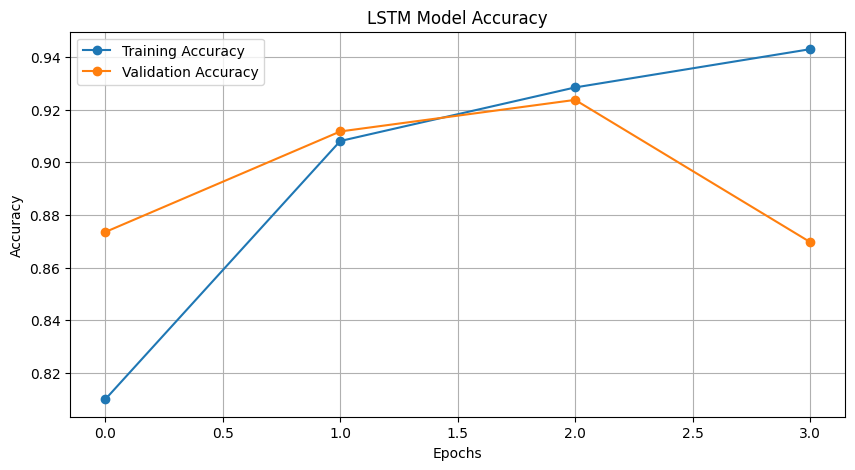

In [93]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    history_new.history['accuracy'],
    label='Training Accuracy',
    marker='o'
)

plt.plot(
    history_new.history['val_accuracy'],
    label='Validation Accuracy',
    marker='o'
)

plt.title('LSTM Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

In [94]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

In [95]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dropout, Dense
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping

model_regularized = Sequential([
    Embedding(
        input_dim=10000,
        output_dim=64,
        mask_zero=True
    ),

    LSTM(
        64,
        recurrent_dropout=0.2,
        kernel_regularizer=l2(0.001)
    ),

    Dropout(0.3),

    Dense(
        1,
        activation='sigmoid',
        kernel_regularizer=l2(0.001)
    )
])

model_regularized.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

early_stop_regularized = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

In [96]:
history_regularized = model_regularized.fit(
    X_train_pad_new,
    y_train,
    epochs=8,
    batch_size=32,
    validation_split=0.2,
    class_weight=class_weights_new,
    callbacks=[early_stop_regularized]
)

Epoch 1/8
397/397 ━━━━━━━━━━━━━━━━━━━━ 29s 61ms/step - accuracy: 0.8241 - loss: 0.4965 - val_accuracy: 0.8603 - val_loss: 0.3774
Epoch 2/8
397/397 ━━━━━━━━━━━━━━━━━━━━ 22s 55ms/step - accuracy: 0.8981 - loss: 0.2885 - val_accuracy: 0.8597 - val_loss: 0.3503
Epoch 3/8
397/397 ━━━━━━━━━━━━━━━━━━━━ 22s 54ms/step - accuracy: 0.9115 - loss: 0.2311 - val_accuracy: 0.8972 - val_loss: 0.2761
Epoch 4/8
397/397 ━━━━━━━━━━━━━━━━━━━━ 21s 53ms/step - accuracy: 0.9356 - loss: 0.1935 - val_accuracy: 0.8165 - val_loss: 0.5240
Epoch 5/8
397/397 ━━━━━━━━━━━━━━━━━━━━ 21s 54ms/step - accuracy: 0.9382 - loss: 0.1759 - val_accuracy: 0.9139 - val_loss: 0.2510
Epoch 6/8
397/397 ━━━━━━━━━━━━━━━━━━━━ 21s 53ms/step - accuracy: 0.9450 - loss: 0.1605 - val_accuracy: 0.8887 - val_loss: 0.3108
Epoch 7/8
397/397 ━━━━━━━━━━━━━━━━━━━━ 21s 53ms/step - accuracy: 0.9577 - loss: 0.1327 - val_accuracy: 0.9227 - val_loss: 0.2544


In [97]:
print("Completed Epochs:",
      len(history_regularized.history['loss']))

print("Best Validation Accuracy:",
      max(history_regularized.history['val_accuracy']))

print("Best Validation Loss:",
      min(history_regularized.history['val_loss']))

Completed Epochs: 7
Best Validation Accuracy: 0.9227373003959656
Best Validation Loss: 0.25102370977401733


In [98]:
test_loss, test_accuracy = model_regularized.evaluate(
    X_test_pad_new,
    y_test
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100)

124/124 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.9132 - loss: 0.2619
Test Loss: 0.2619353234767914
Test Accuracy: 91.32189750671387


In [99]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred_prob_reg = model_regularized.predict(
    X_test_pad_new,
    verbose=0
).flatten()

y_pred_reg = (y_pred_prob_reg >= 0.5).astype(int)

print(classification_report(
    y_test,
    y_pred_reg,
    target_names=["Negative", "Positive"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_reg))

              precision    recall  f1-score   support

    Negative       0.60      0.81      0.69       474
    Positive       0.97      0.93      0.95      3490

    accuracy                           0.91      3964
   macro avg       0.79      0.87      0.82      3964
weighted avg       0.93      0.91      0.92      3964

Confusion Matrix:
[[ 383   91]
 [ 253 3237]]


In [100]:

def predict_my_review():

    review = input("Enter your customer review: ")

    # Text cleaning
    cleaned_review = clean_review(review)

    # Convert text into sequence
    sequence = tokenizer_new.texts_to_sequences([cleaned_review])

    # Padding
    padded = pad_sequences(
        sequence,
        maxlen=100,
        padding='post',
        truncating='post'
    )

    # Prediction
    score = float(
        model_regularized.predict(padded, verbose=0)[0][0]
    )

    # Sentiment result
    if score >= 0.5:
        sentiment = "Positive"
    else:
        sentiment = "Negative"

    print("\n----- SENTIMENT ANALYSIS RESULT -----")
    print("Original Review:", review)
    print("Prediction Score:", round(score, 4))
    print("Predicted Sentiment:", sentiment)


# Test your own review
predict_my_review()


Enter your customer review:  Very beautiful cloth and design



----- SENTIMENT ANALYSIS RESULT -----
Original Review: Very beautiful cloth and design
Prediction Score: 0.3848
Predicted Sentiment: Negative


In [101]:
model_regularized.save("textile_sentiment_lstm.keras")

print("Regularized LSTM Model Saved Successfully!")

Regularized LSTM Model Saved Successfully!


In [102]:
import pickle

with open("textile_tokenizer.pkl", "wb") as file:
    pickle.dump(tokenizer_new, file)

print("Tokenizer Saved Successfully!")

Tokenizer Saved Successfully!


In [103]:
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.sequence import pad_sequences
import pickle

# Load saved model
loaded_model = load_model("textile_sentiment_lstm.keras")

# Load saved tokenizer
with open("textile_tokenizer.pkl", "rb") as file:
    loaded_tokenizer = pickle.load(file)

print("Model Loaded Successfully!")
print("Tokenizer Loaded Successfully!")

Model Loaded Successfully!
Tokenizer Loaded Successfully!


In [104]:
def predict_review(review):

    cleaned = clean_review(review)

    sequence = loaded_tokenizer.texts_to_sequences([cleaned])

    padded = pad_sequences(
        sequence,
        maxlen=100,
        padding="post",
        truncating="post"
    )

    score = float(loaded_model.predict(padded, verbose=0)[0][0])

    sentiment = "Positive" if score >= 0.5 else "Negative"

    print("Customer Review:", review)
    print("Prediction Score:", round(score, 4))
    print("Predicted Sentiment:", sentiment)


predict_review("This dress is beautiful and comfortable")

Customer Review: This dress is beautiful and comfortable
Prediction Score: 0.9031
Predicted Sentiment: Positive


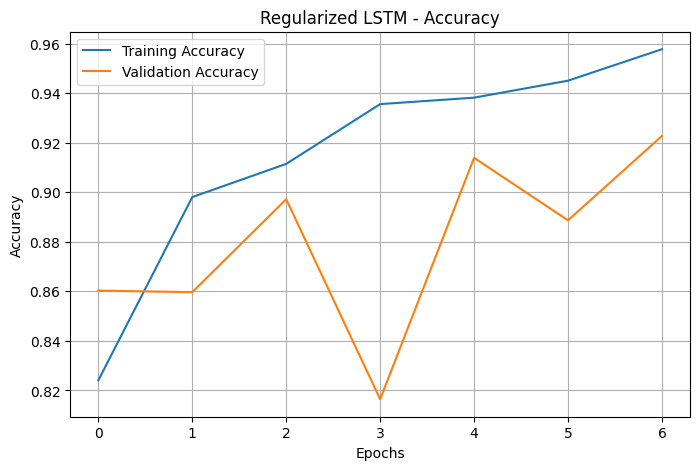

In [105]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history_regularized.history['accuracy'],
         label='Training Accuracy')

plt.plot(history_regularized.history['val_accuracy'],
         label='Validation Accuracy')

plt.title('Regularized LSTM - Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

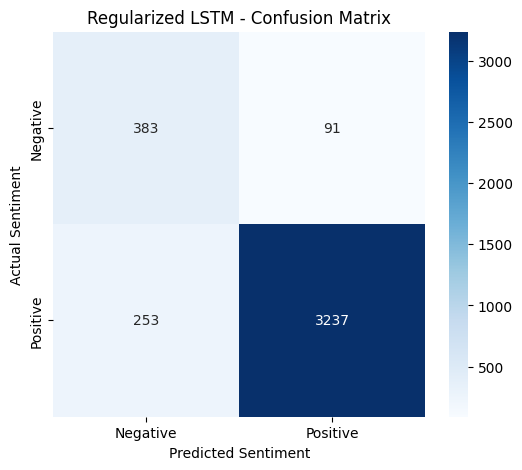

In [106]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_reg)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)

plt.title('Regularized LSTM - Confusion Matrix')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')

plt.show()


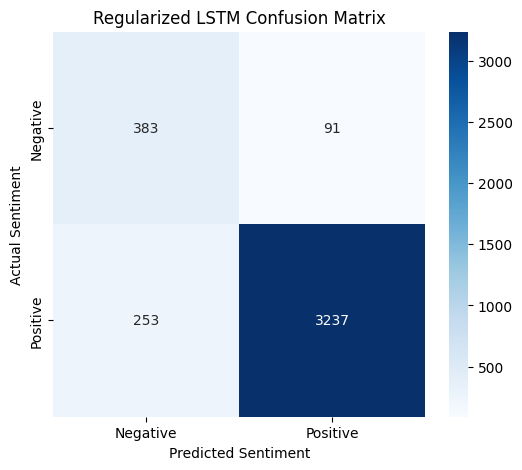

In [107]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)

plt.title('Regularized LSTM Confusion Matrix')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')

plt.savefig('confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

In [108]:
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [109]:
import matplotlib.pyplot as plt
import seaborn as sns

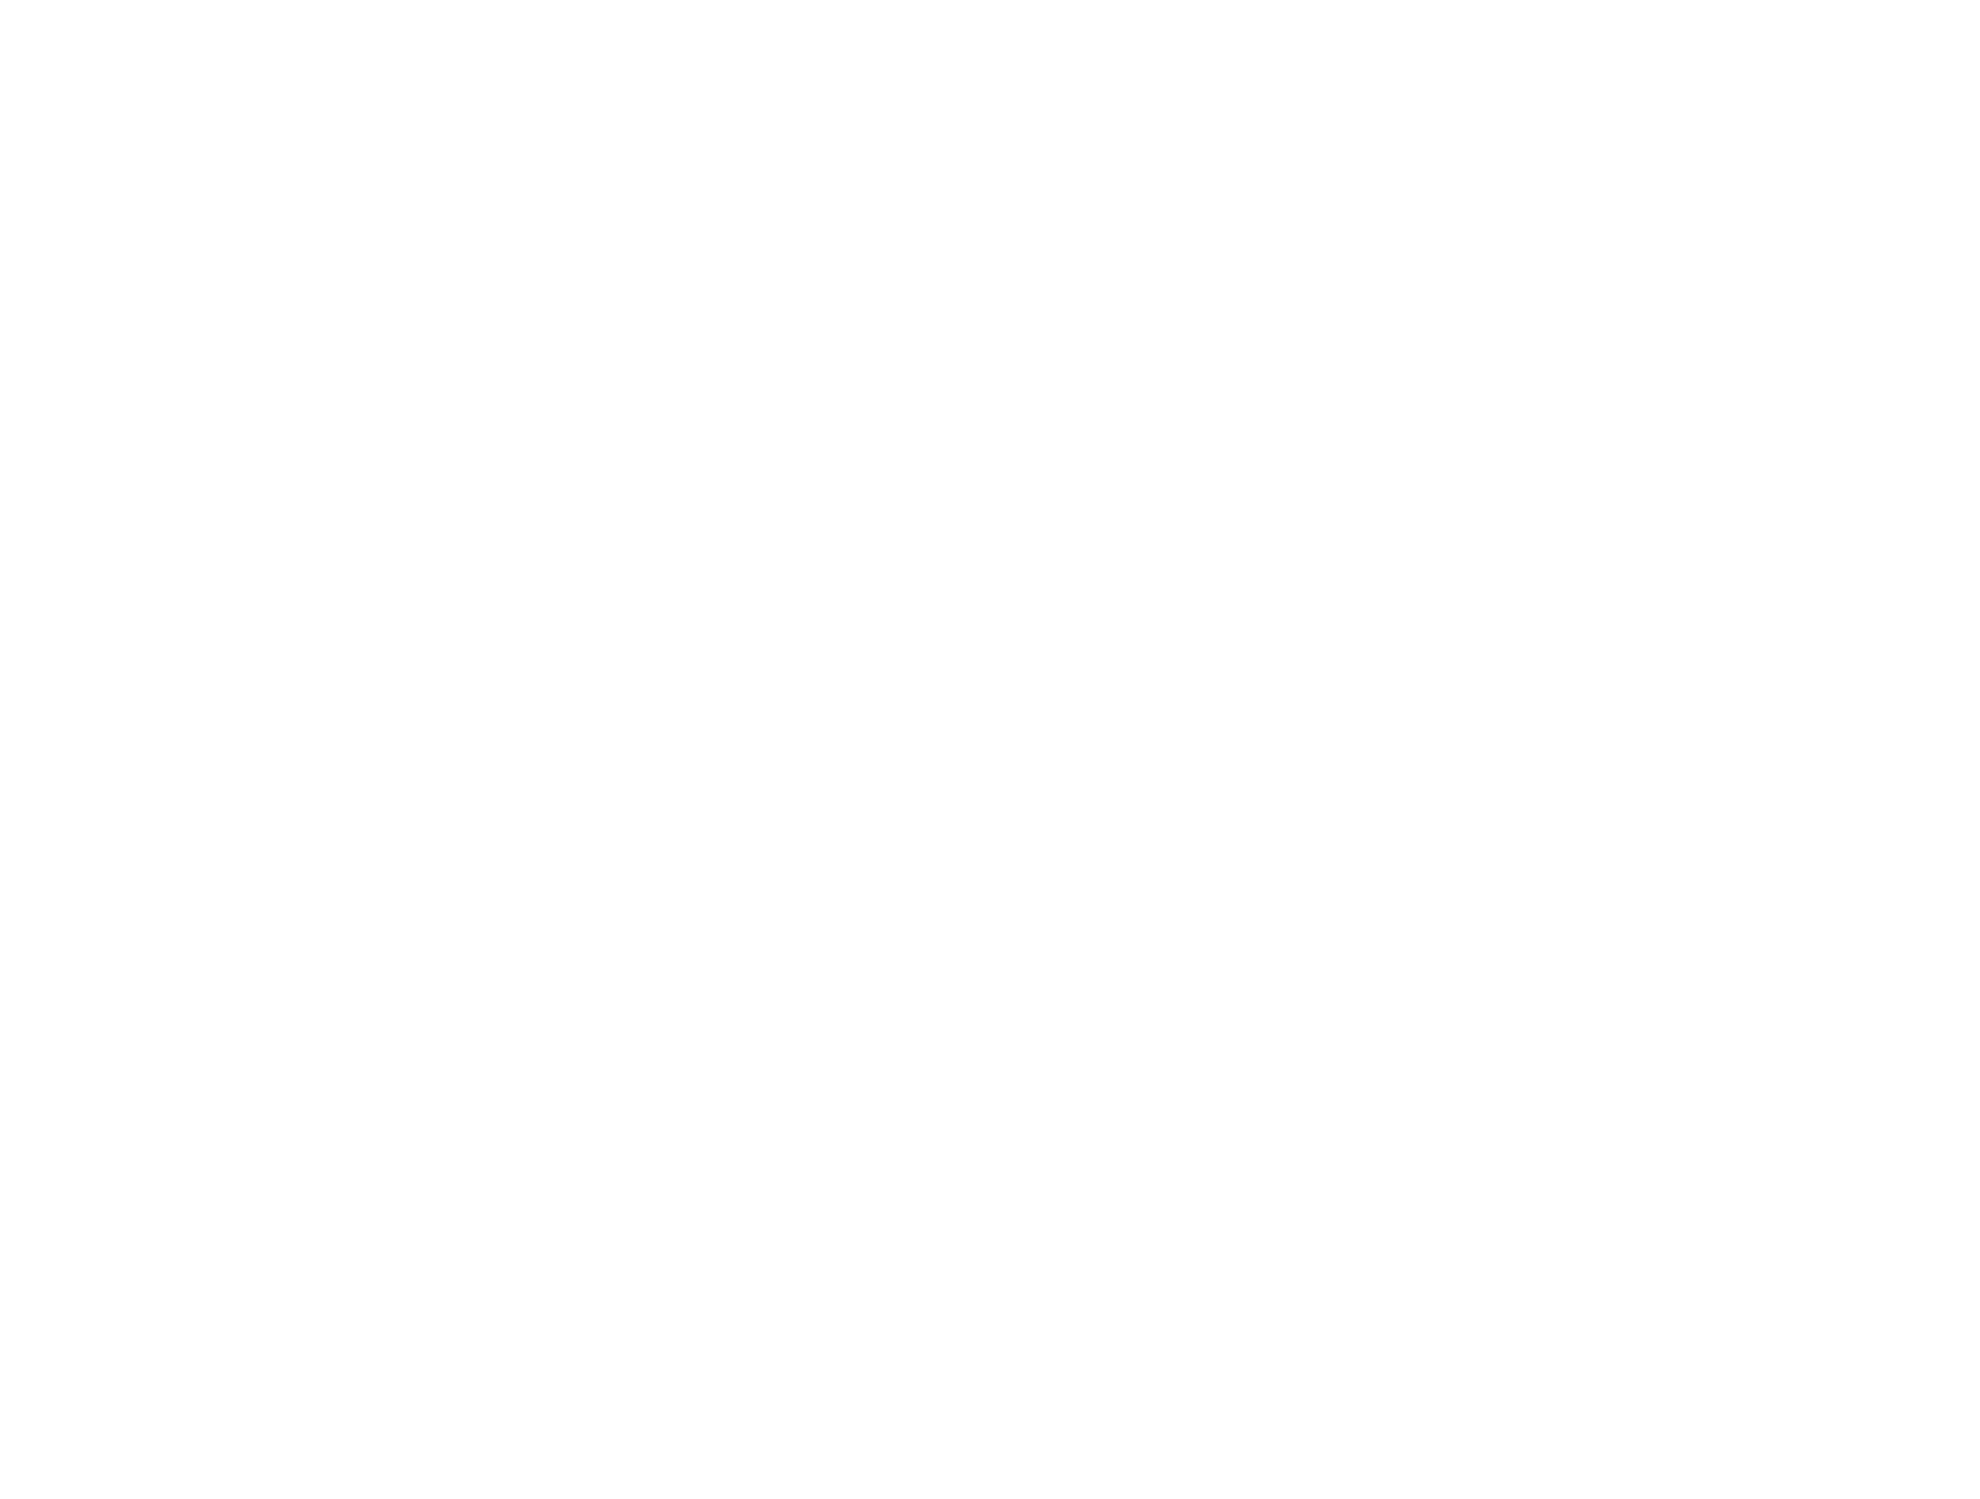

In [110]:
from IPython.display import Image, display

display(Image(filename="confusion_matrix.png"))

In [111]:

import os

# Main project folder
project_folder = "Textile_Sentiment_Analysis"

# Create folders
os.makedirs(project_folder, exist_ok=True)
os.makedirs(os.path.join(project_folder, "models"), exist_ok=True)
os.makedirs(os.path.join(project_folder, "graphs"), exist_ok=True)

print("Project folders created successfully!")
print("Main folder:", os.path.abspath(project_folder))


Project folders created successfully!
Main folder: C:\HOPE AI\AI Course Tamil\Textile Customer Review Sentiment Analysis Using LSTM\Textile_Sentiment_Analysis


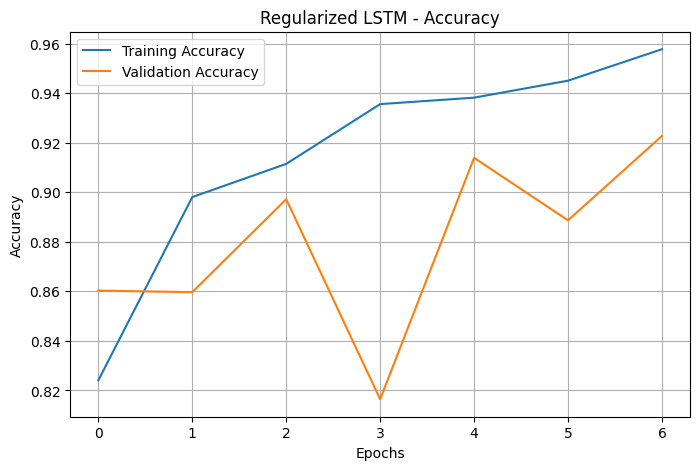

In [112]:
plt.figure(figsize=(8, 5))

plt.plot(history_regularized.history['accuracy'], label='Training Accuracy')
plt.plot(history_regularized.history['val_accuracy'], label='Validation Accuracy')

plt.title('Regularized LSTM - Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(project_folder, "graphs", "accuracy_graph.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

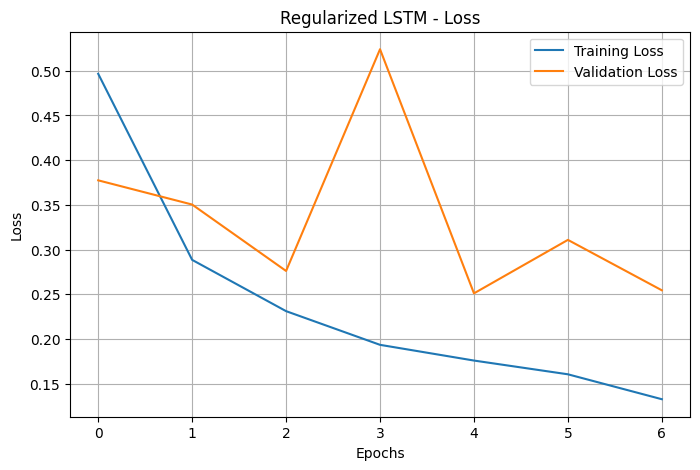

In [113]:
plt.figure(figsize=(8, 5))

plt.plot(history_regularized.history['loss'], label='Training Loss')
plt.plot(history_regularized.history['val_loss'], label='Validation Loss')

plt.title('Regularized LSTM - Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(project_folder, "graphs", "loss_graph.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

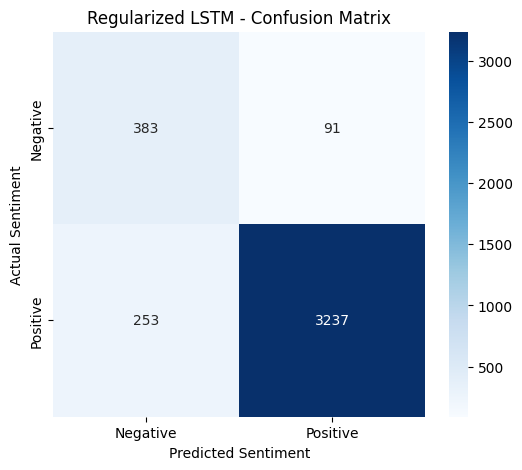

In [114]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)

plt.title('Regularized LSTM - Confusion Matrix')
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')

plt.savefig(
    os.path.join(project_folder, "graphs", "confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [115]:
for root, dirs, files in os.walk(project_folder):
    print("\nFolder:", root)

    for file in files:
        print("  ", file)


Folder: Textile_Sentiment_Analysis

Folder: Textile_Sentiment_Analysis\graphs
   accuracy_graph.png
   confusion_matrix.png
   loss_graph.png

Folder: Textile_Sentiment_Analysis\models


In [116]:

import os
import shutil

project = "Textile_Sentiment_Analysis"

# Create folders
for folder in ["dataset", "models", "graphs"]:
    os.makedirs(os.path.join(project, folder), exist_ok=True)

# Move existing files if they exist
files_to_move = {
    "textile_sentiment_lstm.keras": "models",
    "textile_tokenizer.pkl": "models",
    "confusion_matrix.png": "graphs",
    "Womens Clothing E-Commerce Reviews.csv": "dataset"
}

for filename, folder in files_to_move.items():

    if os.path.exists(filename):
        destination = os.path.join(project, folder, filename)
        shutil.move(filename, destination)
        print("Moved:", filename)

print("\nProject folders organized successfully!")


Moved: textile_sentiment_lstm.keras
Moved: textile_tokenizer.pkl
Moved: confusion_matrix.png
Moved: Womens Clothing E-Commerce Reviews.csv

Project folders organized successfully!


In [117]:

readme_content = """
# Textile Customer Review Sentiment Analysis Using LSTM

## 1. Project Overview
This project classifies textile customer reviews into Positive
and Negative sentiments using Natural Language Processing
and Deep Learning.

## 2. Dataset
Women’s Clothing E-Commerce Reviews dataset.

## 3. Technologies Used
- Python
- Pandas
- NumPy
- NLP
- TensorFlow
- Keras
- LSTM
- Scikit-learn
- Matplotlib
- Seaborn

## 4. Model Architecture
- Embedding Layer
- LSTM Layer
- Dropout
- Dense Layer
- L2 Regularization

## 5. Model Performance
- Test Accuracy: 91.32%
- Test Loss: 0.2619
- Positive F1-score: 0.95
- Negative F1-score: 0.69

## 6. Project Features
- Text preprocessing
- Tokenization and padding
- Sentiment classification
- Customer review prediction
- Confusion matrix visualization

## 7. Conclusion
The Regularized LSTM model achieved 91.32%
test accuracy and successfully classifies
many customer reviews into Positive and Negative sentiments.
"""

readme_path = os.path.join(
    "Textile_Sentiment_Analysis",
    "README.md"
)

with open(readme_path, "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README.md created successfully!")


README.md created successfully!


In [118]:
import os

project_folder = "Textile_Sentiment_Analysis"

for root, dirs, files in os.walk(project_folder):
    level = root.replace(project_folder, "").count(os.sep)
    indent = " " * 4 * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    {file}")

Textile_Sentiment_Analysis/
    README.md
    dataset/
        Womens Clothing E-Commerce Reviews.csv
    graphs/
        accuracy_graph.png
        confusion_matrix.png
        loss_graph.png
    models/
        textile_sentiment_lstm.keras
        textile_tokenizer.pkl


In [119]:
import os

for root, dirs, files in os.walk(
    r"C:\HOPE AI\AI Course Tamil"
):
    for file in files:
        if file in [
            "textile_sentiment_lstm.keras",
            "textile_tokenizer.pkl"
        ]:
            print(os.path.join(root, file))

C:\HOPE AI\AI Course Tamil\Textile Customer Review Sentiment Analysis Using LSTM\Textile_Sentiment_Analysis\models\textile_sentiment_lstm.keras
C:\HOPE AI\AI Course Tamil\Textile Customer Review Sentiment Analysis Using LSTM\Textile_Sentiment_Analysis\models\textile_tokenizer.pkl


In [120]:
# Test one customer review

test_text = "I like this dress"

# Text preprocessing
cleaned = clean_review(test_text)

# Tokenization
sequence = tokenizer_new.texts_to_sequences([cleaned])

# Padding
padded = pad_sequences(
    sequence,
    maxlen=100,
    padding="post",
    truncating="post"
)

# Prediction
score = model_regularized.predict(padded, verbose=0)[0][0]

print("Original Comment:", test_text)
print("Cleaned Comment:", cleaned)
print("Token Sequence:", sequence)
print("Positive Score:", score)

if score >= 0.5:
    print("Prediction: Positive")
else:
    print("Prediction: Negative")

Original Comment: I like this dress
Cleaned Comment: i like this dress
Token Sequence: [[3, 31, 8, 21]]
Positive Score: 0.40512356
Prediction: Negative


In [121]:
test_reviews = [
    "I like this dress",
    "This dress is beautiful",
    "I love this dress",
    "This dress is very nice",
    "I like this product",
    "This dress is comfortable and beautiful"
]

for review in test_reviews:

    cleaned = clean_review(review)

    seq = tokenizer_new.texts_to_sequences([cleaned])

    padded = pad_sequences(
        seq,
        maxlen=100,
        padding="post",
        truncating="post"
    )

    score = model_regularized.predict(padded, verbose=0)[0][0]

    prediction = "Positive" if score >= 0.5 else "Negative"

    print(f"Review: {review}")
    print(f"Positive Score: {score:.4f}")
    print(f"Prediction: {prediction}")
    print("-" * 50)

Review: I like this dress
Positive Score: 0.4051
Prediction: Negative
--------------------------------------------------
Review: This dress is beautiful
Positive Score: 0.5681
Prediction: Positive
--------------------------------------------------
Review: I love this dress
Positive Score: 0.8292
Prediction: Positive
--------------------------------------------------
Review: This dress is very nice
Positive Score: 0.5258
Prediction: Positive
--------------------------------------------------
Review: I like this product
Positive Score: 0.1482
Prediction: Negative
--------------------------------------------------
Review: This dress is comfortable and beautiful
Positive Score: 0.9094
Prediction: Positive
--------------------------------------------------


In [122]:
import re

positive_like = []
negative_like = []

for review, label in zip(X_train_clean, y_train):

    if re.search(r"\blike\b", str(review)):

        if label == 1:
            positive_like.append(review)

        elif label == 0:
            negative_like.append(review)

print("Positive reviews containing 'like':", len(positive_like))
print("Negative reviews containing 'like':", len(negative_like))

print("\n--- Positive Examples ---")
for review in positive_like[:10]:
    print(review)

print("\n--- Negative Examples ---")
for review in negative_like[:10]:
    print(review)

Positive reviews containing 'like': 3221
Negative reviews containing 'like': 640

--- Positive Examples ---
beautiful bohemian maxi that feels like soft woven cotton poly but it is unfortunately viscose the print is as vibrant detailed as expected from hemant nandita color contrast not as bright irl body of dress flares out to an a line after the arm holes and the hem is a shark bite to show off your footwear there is no lining but it does not seem see through very relaxed fit that feels tts but if you prefer a slimmer cut and are of slender body habitus size down otherwise if you are busty
i bought this to wear for my baby shower at weeks i was able to buy it in my size and still get a great fit and the skirt hits right at my bump with the band just above it great option for expecting mothers that can be worn after baby the top is also snug enough to feel like it covers properly could be too snug if you are large chested though
i bought an extra small and i love it i am a size it is w

In [123]:
print("Word index for 'like':",
      tokenizer_new.word_index.get("like"))

print("Word index for 'love':",
      tokenizer_new.word_index.get("love"))

print("Word index for 'beautiful':",
      tokenizer_new.word_index.get("beautiful"))

print("Word index for 'product':",
      tokenizer_new.word_index.get("product"))

Word index for 'like': 31
Word index for 'love': 23
Word index for 'beautiful': 72
Word index for 'product': 733


In [124]:
import re

positive_like = []
negative_like = []

for review, label in zip(X_train_clean, y_train):

    if re.search(r"\blike\b", str(review)):

        if label == 1:
            positive_like.append(review)

        elif label == 0:
            negative_like.append(review)

print("Positive reviews containing like:", len(positive_like))
print("Negative reviews containing like:", len(negative_like))

print("\n--- Positive Examples ---")
for review in positive_like[:10]:
    print(review)

print("\n--- Negative Examples ---")
for review in negative_like[:10]:
    print(review)

Positive reviews containing like: 3221
Negative reviews containing like: 640

--- Positive Examples ---
beautiful bohemian maxi that feels like soft woven cotton poly but it is unfortunately viscose the print is as vibrant detailed as expected from hemant nandita color contrast not as bright irl body of dress flares out to an a line after the arm holes and the hem is a shark bite to show off your footwear there is no lining but it does not seem see through very relaxed fit that feels tts but if you prefer a slimmer cut and are of slender body habitus size down otherwise if you are busty
i bought this to wear for my baby shower at weeks i was able to buy it in my size and still get a great fit and the skirt hits right at my bump with the band just above it great option for expecting mothers that can be worn after baby the top is also snug enough to feel like it covers properly could be too snug if you are large chested though
i bought an extra small and i love it i am a size it is warm 

In [125]:
import re

positive_i_like = []
negative_i_like = []

for review, label in zip(X_train_clean, y_train):

    if re.search(r"\bi like\b", str(review)):

        if label == 1:
            positive_i_like.append(review)

        elif label == 0:
            negative_i_like.append(review)

print("Positive reviews containing 'I like':", len(positive_i_like))
print("Negative reviews containing 'I like':", len(negative_i_like))

print("\n--- Positive I Like Examples ---")
for review in positive_i_like[:10]:
    print(review)

print("\n--- Negative I Like Examples ---")
for review in negative_i_like[:10]:
    print(review)

Positive reviews containing 'I like': 647
Negative reviews containing 'I like': 25

--- Positive I Like Examples ---
the tank is very structured thick yet breathable not see through the coral is much brighter in person and the white is more like a light cream color the white is versatile for all seasons but i like the coral because it is such an unusual color size regular xs is fitted on me not too tight not too loose but over the course of the day it stretches a little and the hem falls at the upper hip i am b waist hips my favorite part is the arm holes are not too big the knit a
this fits me more like a tunic so i wear it with jeggings i am and usually a petite and the s fit well the arms are stretchy which i like since i have an athletic build love the butterfly pattern
i bought this in a beautiful cornflower blue at my retailer store i do not see that color for sale online the blue material was not thin or see through but perhaps the white is the fit is very structured which helps

In [126]:
import re

positive_i_like = []
negative_i_like = []

for review, label in zip(X_train_clean, y_train):

    if re.search(r"\bi like\b", str(review)):

        if label == 1:
            positive_i_like.append(review)

        elif label == 0:
            negative_i_like.append(review)

print("Positive reviews containing 'I like':", len(positive_i_like))
print("Negative reviews containing 'I like':", len(negative_i_like))

print("\n--- Positive I Like Examples ---")
for review in positive_i_like[:10]:
    print(review)

print("\n--- Negative I Like Examples ---")
for review in negative_i_like[:10]:
    print(review)

Positive reviews containing 'I like': 647
Negative reviews containing 'I like': 25

--- Positive I Like Examples ---
the tank is very structured thick yet breathable not see through the coral is much brighter in person and the white is more like a light cream color the white is versatile for all seasons but i like the coral because it is such an unusual color size regular xs is fitted on me not too tight not too loose but over the course of the day it stretches a little and the hem falls at the upper hip i am b waist hips my favorite part is the arm holes are not too big the knit a
this fits me more like a tunic so i wear it with jeggings i am and usually a petite and the s fit well the arms are stretchy which i like since i have an athletic build love the butterfly pattern
i bought this in a beautiful cornflower blue at my retailer store i do not see that color for sale online the blue material was not thin or see through but perhaps the white is the fit is very structured which helps

In [127]:
test_reviews = [
    "I like this dress",
    "I really like this dress",
    "I like this beautiful dress",
    "I like this dress very much",
    "I like this dress because it is beautiful",
    "I like this dress and the quality is excellent"
]

for review in test_reviews:

    cleaned = clean_review(review)

    seq = tokenizer_new.texts_to_sequences([cleaned])

    padded = pad_sequences(
        seq,
        maxlen=100,
        padding="post",
        truncating="post"
    )

    score = model_regularized.predict(padded, verbose=0)[0][0]

    prediction = "Positive" if score >= 0.5 else "Negative"

    print(f"Review: {review}")
    print(f"Positive Score: {score:.4f}")
    print(f"Prediction: {prediction}")
    print("-" * 50)

Review: I like this dress
Positive Score: 0.4051
Prediction: Negative
--------------------------------------------------
Review: I really like this dress
Positive Score: 0.4890
Prediction: Negative
--------------------------------------------------
Review: I like this beautiful dress
Positive Score: 0.5718
Prediction: Positive
--------------------------------------------------
Review: I like this dress very much
Positive Score: 0.3362
Prediction: Negative
--------------------------------------------------
Review: I like this dress because it is beautiful
Positive Score: 0.5081
Prediction: Positive
--------------------------------------------------
Review: I like this dress and the quality is excellent
Positive Score: 0.5233
Prediction: Positive
--------------------------------------------------


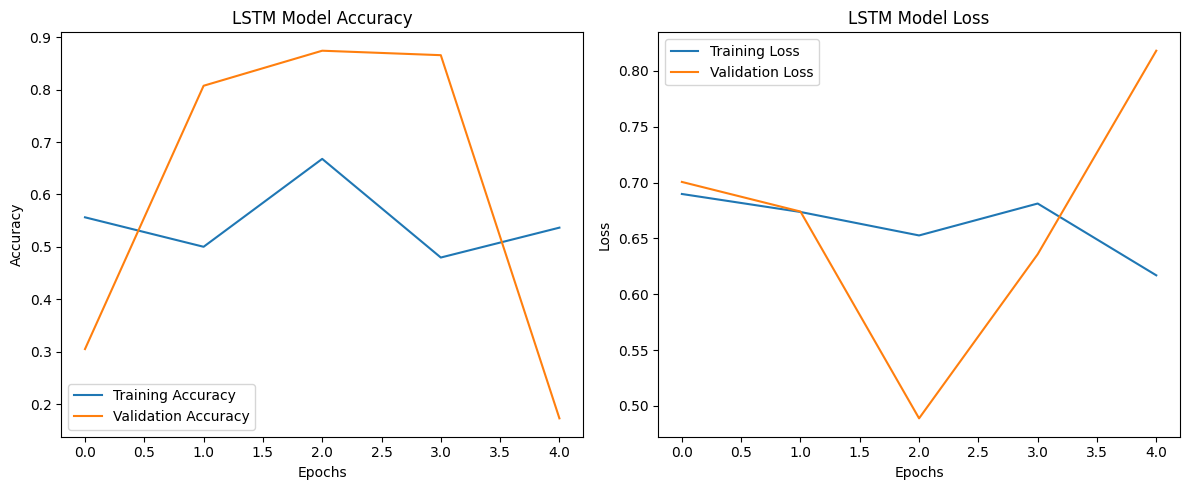

In [128]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('LSTM Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('LSTM Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [129]:
print("History keys:")
print(history.history.keys())

print("\nNumber of epochs:",
      len(history.history['accuracy']))

print("\nTraining Accuracy:",
      history.history['accuracy'])

print("\nValidation Accuracy:",
      history.history['val_accuracy'])

print("\nTraining Loss:",
      history.history['loss'])

print("\nValidation Loss:",
      history.history['val_loss'])

History keys:
dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

Number of epochs: 5

Training Accuracy: [0.5563352704048157, 0.5001182556152344, 0.667823076248169, 0.4796184003353119, 0.5366238355636597]

Validation Accuracy: [0.30495113134384155, 0.8073163032531738, 0.8741722106933594, 0.8656575083732605, 0.17281614243984222]

Training Loss: [0.6898056268692017, 0.6736919283866882, 0.6526672840118408, 0.68125319480896, 0.6169434785842896]

Validation Loss: [0.7006120681762695, 0.6740756034851074, 0.4888346195220947, 0.6358271241188049, 0.8181414008140564]


In [130]:
model_regularized.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)              │ (None, 100, 64)             │         640,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_4 (LSTM)                        │ (None, 64)                  │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,019,269 (7.70 MB)

 Trainable params: 673,089 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,346,180 (5.14 MB)

In [131]:
import numpy as np

print("Training class distribution:")
print(np.unique(y_train, return_counts=True))

print("\nValidation class distribution:")
print(np.unique(y_val, return_counts=True))

Training class distribution:
(array([0, 1]), array([ 1896, 13958]))

Validation class distribution:


NameError: name 'y_val' is not defined

In [132]:
%whos

Variable                 Type                      Data/Info
------------------------------------------------------------
ConfusionMatrixDisplay   type                      <class 'sklearn.metrics._<...>.ConfusionMatrixDisplay'>
Counter                  type                      <class 'collections.Counter'>
Dense                    type                      <class 'keras.src.layers.core.dense.Dense'>
Dropout                  type                      <class 'keras.src.layers.<...>ization.dropout.Dropout'>
ENGLISH_STOP_WORDS       frozenset                 frozenset({'same', 'with'<...>'to', 'herself', 'them'})
EarlyStopping            type                      <class 'keras.src.callbac<...>_stopping.EarlyStopping'>
Embedding                type                      <class 'keras.src.layers.<...>ore.embedding.Embedding'>
Image                    type                      <class 'IPython.core.display.Image'>
LSTM                     type                      <class 'keras.src.layers.rnn

In [133]:
for name, hist in [
    ("history", history),
    ("history_new", history_new),
    ("history_regularized", history_regularized)
]:
    print("\n", name)
    print("Epochs:", len(hist.history["accuracy"]))
    print("Training Accuracy:", hist.history["accuracy"])
    print("Validation Accuracy:", hist.history["val_accuracy"])
    print("Validation Loss:", hist.history["val_loss"])


 history
Epochs: 5
Training Accuracy: [0.5563352704048157, 0.5001182556152344, 0.667823076248169, 0.4796184003353119, 0.5366238355636597]
Validation Accuracy: [0.30495113134384155, 0.8073163032531738, 0.8741722106933594, 0.8656575083732605, 0.17281614243984222]
Validation Loss: [0.7006120681762695, 0.6740756034851074, 0.4888346195220947, 0.6358271241188049, 0.8181414008140564]

 history_new
Epochs: 4
Training Accuracy: [0.8100607395172119, 0.908065915107727, 0.9284080862998962, 0.9429157376289368]
Validation Accuracy: [0.8735414743423462, 0.9116997718811035, 0.9236834049224854, 0.8697571754455566]
Validation Loss: [0.29592496156692505, 0.214140847325325, 0.22158843278884888, 0.3143765330314636]

 history_regularized
Epochs: 7
Training Accuracy: [0.8240952491760254, 0.8980525135993958, 0.911456286907196, 0.9355830550193787, 0.9381849765777588, 0.9450445771217346, 0.9577386975288391]
Validation Accuracy: [0.8602964282035828, 0.8596656918525696, 0.8971933126449585, 0.8164616823196411, 0.

In [134]:
print("EarlyStopping configuration:")
print("Monitor:", early_stop_regularized.monitor)
print("Patience:", early_stop_regularized.patience)
print("Restore best weights:",
      early_stop_regularized.restore_best_weights)

EarlyStopping configuration:
Monitor: val_loss
Patience: 2
Restore best weights: True


In [135]:
print("Model name:", model_regularized.name)

print("Test accuracy:", test_accuracy)

print("Test loss:", test_loss)

print("Tokenizer vocabulary size:",
      len(tokenizer_new.word_index))

Model name: sequential_4
Test accuracy: 0.9132189750671387
Test loss: 0.2619353234767914
Tokenizer vocabulary size: 11735


In [136]:
# Save the verified Regularized LSTM model
model_regularized.save(
    r"C:\HOPE AI\AI Course Tamil\Textile Customer Review Sentiment Analysis Using LSTM\Textile_Sentiment_Analysis\models\textile_sentiment_lstm.keras"
)

# Save the matching tokenizer
import pickle

with open(
    r"C:\HOPE AI\AI Course Tamil\Textile Customer Review Sentiment Analysis Using LSTM\Textile_Sentiment_Analysis\models\textile_tokenizer.pkl",
    "wb"
) as file:
    pickle.dump(tokenizer_new, file)

print("Model and Tokenizer Saved Successfully!")

Model and Tokenizer Saved Successfully!


In [137]:
from tensorflow.keras.models import load_model
import pickle

MODEL_PATH = r"C:\HOPE AI\AI Course Tamil\Textile Customer Review Sentiment Analysis Using LSTM\Textile_Sentiment_Analysis\models\textile_sentiment_lstm.keras"

TOKENIZER_PATH = r"C:\HOPE AI\AI Course Tamil\Textile Customer Review Sentiment Analysis Using LSTM\Textile_Sentiment_Analysis\models\textile_tokenizer.pkl"

# Load saved model
loaded_model = load_model(MODEL_PATH)

# Load saved tokenizer
with open(TOKENIZER_PATH, "rb") as file:
    loaded_tokenizer = pickle.load(file)

print("Model loaded successfully!")
print("Tokenizer loaded successfully!")

Model loaded successfully!
Tokenizer loaded successfully!


In [138]:
test_text = "I like this dress"

cleaned = clean_review(test_text)

sequence = loaded_tokenizer.texts_to_sequences([cleaned])

padded = pad_sequences(
    sequence,
    maxlen=100,
    padding="post",
    truncating="post"
)

score = loaded_model.predict(padded, verbose=0)[0][0]

print("Original Review:", test_text)
print("Cleaned Review:", cleaned)
print("Positive Score:", round(float(score), 4))
print("Prediction:", "Positive" if score >= 0.5 else "Negative")

Original Review: I like this dress
Cleaned Review: i like this dress
Positive Score: 0.4051
Prediction: Negative


In [139]:
test_reviews = [
    "I love this dress",
    "This dress is beautiful",
    "I like this dress",
    "This dress is very comfortable",
    "I hate this dress"
]

for review in test_reviews:

    cleaned = clean_review(review)

    sequence = loaded_tokenizer.texts_to_sequences([cleaned])

    padded = pad_sequences(
        sequence,
        maxlen=100,
        padding="post",
        truncating="post"
    )

    score = loaded_model.predict(padded, verbose=0)[0][0]

    prediction = "Positive" if score >= 0.5 else "Negative"

    print(f"\nReview: {review}")
    print(f"Positive Score: {score:.4f}")
    print(f"Prediction: {prediction}")


Review: I love this dress
Positive Score: 0.8292
Prediction: Positive

Review: This dress is beautiful
Positive Score: 0.5681
Prediction: Positive

Review: I like this dress
Positive Score: 0.4051
Prediction: Negative

Review: This dress is very comfortable
Positive Score: 0.8341
Prediction: Positive

Review: I hate this dress
Positive Score: 0.3570
Prediction: Negative


In [140]:
import numpy as np
import pandas as pd

# Predict using the saved model
y_prob = loaded_model.predict(X_test_pad, verbose=0).flatten()

# Apply threshold
y_pred = (y_prob >= 0.5).astype(int)

# Find incorrect predictions
wrong_indices = np.where(y_test != y_pred)[0]

error_df = pd.DataFrame({
    "Actual": y_test.iloc[wrong_indices].values
        if hasattr(y_test, "iloc") else y_test[wrong_indices],
    "Predicted": y_pred[wrong_indices],
    "Positive_Score": y_prob[wrong_indices],
    "Review": X_test.iloc[wrong_indices].values
        if hasattr(X_test, "iloc") else X_test[wrong_indices]
})

print("Total incorrect predictions:", len(error_df))
display(error_df.head(15))

Total incorrect predictions: 783


,Actual,Predicted,Positive_Score,Review
0,0,1,0.998220,I bought this top in the blue motif and loved ...
1,0,1,0.991753,"I was so excited when i ordered this, i love c..."
2,0,1,0.813621,The back of this t-shirt looks cute but the fr...
3,1,0,0.153009,This shirt is a very cute dressed up casual ki...
4,0,1,0.916388,"This top is has an awkward neckline, doesn't l..."
5,0,1,0.559193,Had to return. ordered an xs which usually fit...
6,0,1,0.752955,Not a pretty blouse - it's quite utilitarian i...
7,0,1,0.739243,I love the color block concept but this top wa...
8,1,0,0.320684,I would have liked it but it was too small for...
9,0,1,0.994045,"Fits large, wrinkles easily and not what i exp..."


In [141]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Predict using the saved model
y_prob_check = loaded_model.predict(
    X_test_pad, verbose=0
).flatten()

# Use the same threshold
y_pred_check = (y_prob_check >= 0.5).astype(int)

# Calculate metrics again
print("Test samples:", len(y_test))
print("Predictions:", len(y_pred_check))

print(
    "Recalculated Accuracy:",
    accuracy_score(y_test, y_pred_check)
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_check))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_check))

Test samples: 3964
Predictions: 3964
Recalculated Accuracy: 0.8024722502522704

Confusion Matrix:
[[  60  414]
 [ 369 3121]]

Classification Report:
              precision    recall  f1-score   support

           0       0.14      0.13      0.13       474
           1       0.88      0.89      0.89      3490

    accuracy                           0.80      3964
   macro avg       0.51      0.51      0.51      3964
weighted avg       0.79      0.80      0.80      3964



In [142]:
import numpy as np
from sklearn.metrics import accuracy_score

# Original Regularized LSTM prediction
original_prob = model_regularized.predict(
    X_test_pad, verbose=0
).flatten()

# Saved LSTM prediction
saved_prob = loaded_model.predict(
    X_test_pad, verbose=0
).flatten()

# Compare predictions
original_pred = (original_prob >= 0.5).astype(int)
saved_pred = (saved_prob >= 0.5).astype(int)

print("Original Model Accuracy:",
      accuracy_score(y_test, original_pred))

print("Saved Model Accuracy:",
      accuracy_score(y_test, saved_pred))

print("Are probabilities identical?",
      np.allclose(original_prob, saved_prob, atol=1e-6))

print("Maximum probability difference:",
      np.max(np.abs(original_prob - saved_prob)))

Original Model Accuracy: 0.8024722502522704
Saved Model Accuracy: 0.8024722502522704
Are probabilities identical? True
Maximum probability difference: 1.1920929e-07


In [143]:
print("X_test_pad shape:", X_test_pad.shape)
print("X_test_pad_new shape:", X_test_pad_new.shape)

print("Are test sequences identical?",
      np.array_equal(X_test_pad, X_test_pad_new))

X_test_pad shape: (3964, 100)
X_test_pad_new shape: (3964, 100)
Are test sequences identical? False


In [144]:
print("Original tokenizer vocabulary:",
      len(tokenizer.word_index))

print("New tokenizer vocabulary:",
      len(tokenizer_new.word_index))

print("\nOriginal tokenizer sample:")
print(tokenizer.word_index.get("dress"))

print("\nNew tokenizer sample:")
print(tokenizer_new.word_index.get("dress"))

Original tokenizer vocabulary: 12736
New tokenizer vocabulary: 11735

Original tokenizer sample:
19

New tokenizer sample:
21


In [145]:
print("Original tokenizer + original test data:")
print(X_test_pad[0][:30])

print("\nNew tokenizer + new test data:")
print(X_test_pad_new[0][:30])

print("\nOriginal model accuracy on original test data:")
print(model.evaluate(X_test_pad, y_test, verbose=0))

print("\nNew model accuracy on new test data:")
print(model_new.evaluate(X_test_pad_new, y_test, verbose=0))

print("\nRegularized model accuracy on regularized test data:")
print(model_regularized.evaluate(X_test_pad, y_test, verbose=0))

Original tokenizer + original test data:
[   3  993    8   42  663    2    1 1761    4   24  266    9  212   17
   23  282    3   18 3091    8  365    3 1420    8   54    5 2508   68
    6    7]

New tokenizer + new test data:
[   3  931    8   42  627    2 9855 1658    4   26  254    9  205   20
   25    3   19 2920    8  349    3 1336    8   52    6 2367   68    5
    7   11]

Original model accuracy on original test data:
[0.8212875127792358, 0.16069626808166504]

New model accuracy on new test data:
[0.21567878127098083, 0.9109485149383545]

Regularized model accuracy on regularized test data:
[0.6460126042366028, 0.8024722337722778]


In [147]:
# Correct Regularized LSTM evaluation
test_loss, test_accuracy = model_regularized.evaluate(
    X_test_pad_new,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100)

Test Loss: 0.2619353234767914
Test Accuracy: 91.32189750671387


In [148]:
test_reviews = [
    "LIKE",
    "I like this dress",
    "I really like this beautiful dress",
    "I don't like this dress"
]

for review in test_reviews:
    cleaned = clean_review(review)

    sequence = tokenizer_new.texts_to_sequences([cleaned])

    padded = pad_sequences(
        sequence,
        maxlen=100,
        padding="post",
        truncating="post"
    )

    score = model_regularized.predict(
        padded, verbose=0
    )[0][0]

    prediction = "Positive" if score >= 0.5 else "Negative"

    print(f"\nReview: {review}")
    print(f"Positive Score: {score:.4f}")
    print(f"Prediction: {prediction}")


Review: LIKE
Positive Score: 0.4433
Prediction: Negative

Review: I like this dress
Positive Score: 0.4051
Prediction: Negative

Review: I really like this beautiful dress
Positive Score: 0.6547
Prediction: Positive

Review: I don't like this dress
Positive Score: 0.1908
Prediction: Negative
